# Réseau Neuronal Analogique — Visualisation v8

Adapté pour les réseaux **1 sortie** entraînés en v8.

**Corrections vs notebook original :**
- `Itot < rheobase` → `Fout = 0 Hz` (neurone silencieux, pas d'extrapolation)
- Decision map : `Fout ≥ seuil → classe 1` (pas d'argmax multi-sortie)
- Confiance : `|Fout − seuil|` en kHz
- Espace d'entrée : `[-1, 1]²` converti en tension via `xy_to_voltage`
- Diagnostic Itot par couche (plage neurone + % silencieux + % saturé)

## 0. Imports

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.colors as mcolors
from matplotlib.patches import Circle
from matplotlib.colors import TwoSlopeNorm

%matplotlib inline
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 11

INPUT_CSV   = 'input_min_conso.csv'
NEURON_CSV  = 'neuron.csv'
SYN_EXC_CSV = 'excitation20.csv'
SYN_INH_CSV = 'inhibition20.csv'
FREQ_MERGE_TOL_HZ = 1000.0

## 1. Fonctions de base

In [16]:
def read_cadence_rows(csv_path):
    df = pd.read_csv(csv_path)
    if 'Parameter' not in df.columns:
        raise ValueError(f"{csv_path}: colonne 'Parameter' introuvable")
    data_cols = [c for c in df.columns if c not in ['Parameter', 'Unnamed: 1']]
    def get_row(row_name, allow_non_numeric=False):
        row = df.loc[df['Parameter'] == row_name, data_cols]
        if row.empty:
            raise ValueError(f"Ligne '{row_name}' introuvable dans {csv_path}")
        values = pd.to_numeric(row.iloc[0], errors='coerce').to_numpy(dtype=float)
        return values
    return get_row

def get_clean_rows(reader, row_names):
    rows = [reader(name, allow_non_numeric=True) for name in row_names]
    mask = np.all(np.isfinite(np.vstack(rows)), axis=0)
    return [r[mask] for r in rows], mask

def interp_clip(x, xp, fp):
    return np.interp(np.asarray(x, float), xp, fp, left=fp[0], right=fp[-1])

def interp2d_bilinear(x, y, x_axis, y_axis, z_grid):
    x = float(np.clip(x, x_axis[0], x_axis[-1]))
    y = float(np.clip(y, y_axis[0], y_axis[-1]))
    ix = int(np.clip(np.searchsorted(x_axis, x) - 1, 0, len(x_axis) - 2))
    iy = int(np.clip(np.searchsorted(y_axis, y) - 1, 0, len(y_axis) - 2))
    x1, x2 = x_axis[ix], x_axis[ix + 1]
    y1, y2 = y_axis[iy], y_axis[iy + 1]
    tx = 0.0 if x2 == x1 else (x - x1) / (x2 - x1)
    ty = 0.0 if y2 == y1 else (y - y1) / (y2 - y1)
    return (z_grid[ix,iy]*(1-tx)*(1-ty) + z_grid[ix+1,iy]*tx*(1-ty)
          + z_grid[ix,iy+1]*(1-tx)*ty   + z_grid[ix+1,iy+1]*tx*ty)

def strictly_monotonic_branch(x, y):
    idx = int(np.argmax(y))
    xm, ym = np.asarray(x[:idx+1], float), np.asarray(y[:idx+1], float)
    o = np.argsort(xm)
    return xm[o], ym[o]

def merge_close_values(values, tol):
    vals = np.sort(np.asarray(values, float))
    groups = [[vals[0]]]
    for v in vals[1:]:
        if abs(v - np.mean(groups[-1])) <= tol: groups[-1].append(v)
        else: groups.append([v])
    return np.array([np.mean(g) for g in groups])

def snap_to_axis(values, axis):
    return np.array([axis[np.argmin(np.abs(axis - v))] for v in np.asarray(values, float)])

def build_grid_tolerant(W_all, F_all, Y_all, freq_tol=1000.0):
    W_all, F_all, Y_all = map(lambda a: np.asarray(a, float), [W_all, F_all, Y_all])
    W_unique = np.unique(W_all)
    F_axis   = merge_close_values(np.unique(F_all), tol=freq_tol)
    F_snap   = snap_to_axis(F_all, F_axis)
    z_grid   = np.empty((len(W_unique), len(F_axis)))
    for i, w in enumerate(W_unique):
        for j, f in enumerate(F_axis):
            mask = np.isclose(W_all, w) & np.isclose(F_snap, f)
            z_grid[i, j] = np.mean(Y_all[mask])
    return W_unique, F_axis, z_grid

print('Fonctions de base OK.')

Fonctions de base OK.


## 2. Chargement des modèles Cadence

In [17]:
inp = read_cadence_rows(INPUT_CSV)
VEX_IN, FSPIKES_IN = inp('Vex'), inp('Fspikes')
INPUT_V_AXIS, INPUT_F_AXIS = strictly_monotonic_branch(VEX_IN, FSPIKES_IN)

neuro = read_cadence_rows(NEURON_CSV)
IEX_NEURO, FSPIKES_NEURO = neuro('Iex'), neuro('Fspikes')
NEURON_I_AXIS, NEURON_F_AXIS = strictly_monotonic_branch(IEX_NEURO, FSPIKES_NEURO)

syn_exc = read_cadence_rows(SYN_EXC_CSV)
(W2_EXC, FPRE_EXC, IPOST_EXC), _ = get_clean_rows(syn_exc, ['W2', 'Fpre', 'Ipost'])
W_EXC_AXIS, F_EXC_AXIS, IPOST_EXC_GRID = build_grid_tolerant(W2_EXC, FPRE_EXC, IPOST_EXC)

syn_inh = read_cadence_rows(SYN_INH_CSV)
(W2_INH, FPRE_INH, IPOST_INH), _ = get_clean_rows(syn_inh, ['W2', 'Fpre', 'Ipost'])
W_INH_AXIS, F_INH_AXIS, IPOST_INH_GRID = build_grid_tolerant(W2_INH, FPRE_INH, IPOST_INH)

V_MIN = float(INPUT_V_AXIS[0])
V_MAX = float(INPUT_V_AXIS[-1])
NEURON_I_RHEOBASE = float(NEURON_I_AXIS[0])
NEURON_I_MAX      = float(NEURON_I_AXIS[-1])
NEURON_F_MAX      = float(NEURON_F_AXIS[-1])

print(f'Input  V : [{V_MIN*1e3:.1f}, {V_MAX*1e3:.1f}] mV')
print(f'Neurone  : [{NEURON_I_AXIS[0]*1e12:.1f}, {NEURON_I_MAX*1e12:.1f}] pA → [{NEURON_F_AXIS[0]/1e3:.1f}, {NEURON_F_MAX/1e3:.1f}] kHz')
print(f'Rheobase : {NEURON_I_RHEOBASE*1e12:.2f} pA')
print(f'EXC W    : {W_EXC_AXIS} um')
print(f'INH W    : {W_INH_AXIS} um')
print('Modèles Cadence chargés.')

Input  V : [-100.0, 100.0] mV
Neurone  : [3.0, 1000.0] pA → [3.1, 193.1] kHz
Rheobase : 3.00 pA
EXC W    : [0.135  0.2858 0.4366 0.5874 0.7382 0.8889 1.04   1.191  1.341  1.492
 1.643  1.794  1.944  2.095  2.246  2.397  2.548  2.698  2.849  3.    ] um
INH W    : [0.135  0.1805 0.2261 0.2716 0.3171 0.3626 0.4082 0.4537 0.4992 0.5447
 0.5903 0.6358 0.6813 0.7268 0.7724 0.8179 0.8634 0.9089 0.9545 1.    ] um
Modèles Cadence chargés.


## 3. Fonctions neurone et synapses

**Correction v8 :** `neuron_f_of_i` retourne `0 Hz` si `Itot < rheobase`  
(le neurone est silencieux — pas d'extrapolation incorrecte)

In [18]:
def input_f_of_v(Vin_V):
    """Tension → fréquence (bloc d'entrée)."""
    return float(interp_clip(Vin_V, INPUT_V_AXIS, INPUT_F_AXIS))

def neuron_f_of_i(Iin_A):
    """
    Courant → fréquence (neurone interne).
    FIX v8 : si Iin < rheobase → 0 Hz (neurone silencieux).
    Le notebook original utilisait interp_clip qui retournait F[0] ≠ 0.
    """
    Iin_A = float(Iin_A)
    if Iin_A < NEURON_I_RHEOBASE:
        return 0.0
    return float(interp_clip(Iin_A, NEURON_I_AXIS, NEURON_F_AXIS))

def isyn_exc(Fpre_Hz, Wexc_um):
    return interp2d_bilinear(Wexc_um, Fpre_Hz, W_EXC_AXIS, F_EXC_AXIS, IPOST_EXC_GRID)

def isyn_inh(Fpre_Hz, Winh_um):
    return interp2d_bilinear(Winh_um, Fpre_Hz, W_INH_AXIS, F_INH_AXIS, IPOST_INH_GRID)

# Vérification du fix
print('=== Vérification neuron_f_of_i ===')
print(f'  Itot = -10 pA  → {neuron_f_of_i(-10e-12)/1e3:.2f} kHz  (attendu: 0.00 kHz)')
print(f'  Itot =   0 pA  → {neuron_f_of_i(0)/1e3:.2f} kHz  (attendu: 0.00 kHz)')
print(f'  Itot = rheo    → {neuron_f_of_i(NEURON_I_RHEOBASE)/1e3:.2f} kHz  (attendu: {NEURON_F_AXIS[0]/1e3:.2f} kHz)')
print(f'  Itot = 50 pA   → {neuron_f_of_i(50e-12)/1e3:.2f} kHz')
print(f'  Itot = I_max   → {neuron_f_of_i(NEURON_I_MAX)/1e3:.2f} kHz  (attendu: {NEURON_F_MAX/1e3:.2f} kHz)')

=== Vérification neuron_f_of_i ===
  Itot = -10 pA  → 0.00 kHz  (attendu: 0.00 kHz)
  Itot =   0 pA  → 0.00 kHz  (attendu: 0.00 kHz)
  Itot = rheo    → 3.08 kHz  (attendu: 3.08 kHz)
  Itot = 50 pA   → 40.42 kHz
  Itot = I_max   → 193.10 kHz  (attendu: 193.10 kHz)


## 4. Couche forward

In [19]:
def layer_forward(Fin_vec_Hz, sign_matrix, width_matrix_um):
    """
    Propagation d'une couche.
    Fin_vec_Hz      : (N,)    fréquences pré-synaptiques [Hz]
    sign_matrix     : (N, M)  +1 excitateur, -1 inhibiteur
    width_matrix_um : (N, M)  largeurs synapses [µm]
    Retourne : Fout (M,), Iconn (N,M), Itot (M,)
    """
    N = len(Fin_vec_Hz)
    M = sign_matrix.shape[1]
    Iconn_mat = np.zeros((N, M))
    for i in range(N):
        for j in range(M):
            s, w = sign_matrix[i, j], width_matrix_um[i, j]
            if s == 1:
                Iconn_mat[i, j] = float(isyn_exc(Fin_vec_Hz[i], w))
            elif s == -1:
                Iconn_mat[i, j] = -float(isyn_inh(Fin_vec_Hz[i], w))
    Itot = np.sum(Iconn_mat, axis=0)
    # FIX : neuron_f_of_i retourne 0 si Itot < rheobase
    Fout = np.array([neuron_f_of_i(it) for it in Itot])
    return Fout, Iconn_mat, Itot

print('layer_forward OK.')

layer_forward OK.


## 5. Configuration du réseau v8

Colle ici les poids exportés par `weights_cadence_disk_v8.csv`  
et le seuil depuis `threshold_cadence_disk_v8.csv`.

**Architecture v8 :** `[2, N_HIDDEN, 1]` — 1 seule sortie  
**Décision :** `Fout ≥ THRESHOLD_HZ → classe 1 (intérieur)`

In [20]:
# ╔══════════════════════════════════════════════════════════╗
# ║         COLLER LES POIDS ICI (depuis v8)                ║
# ╚══════════════════════════════════════════════════════════╝

# Option A : charger depuis CSV exporté par v8
LOAD_FROM_CSV = True   # mettre False pour entrer les poids manuellement

WEIGHTS_CSV   = 'weights_cadence_disk_v8.csv'
THRESHOLD_CSV = 'threshold_cadence_disk_v8.csv'

if LOAD_FROM_CSV:
    df_w = pd.read_csv(WEIGHTS_CSV)
    df_t = pd.read_csv(THRESHOLD_CSV)
    THRESHOLD_HZ = float(df_t['threshold_Hz'].iloc[0])

    # Reconstruire signs et widths par couche
    layers_config = []
    for li in sorted(df_w['layer'].unique()):
        sub = df_w[df_w['layer'] == li]
        n_in  = sub['pre'].max()  + 1
        n_out = sub['post'].max() + 1
        signs  = np.zeros((n_in, n_out), dtype=int)
        widths = np.zeros((n_in, n_out))
        for _, row in sub.iterrows():
            signs [int(row['pre']), int(row['post'])] = int(row['sign'])
            widths[int(row['pre']), int(row['post'])] = float(row['width_um'])
        layers_config.append({'signs': signs, 'widths': widths})

    layer_sizes = [2] + [cfg['signs'].shape[1] for cfg in layers_config]
    print(f'Chargé depuis CSV : architecture={layer_sizes}')
    print(f'Seuil de décision : {THRESHOLD_HZ/1e3:.3f} kHz')
    if 'bal_acc_train' in df_t.columns:
        print(f'bal_acc train={df_t["bal_acc_train"].iloc[0]:.4f}  '
              f'test={df_t["bal_acc_test"].iloc[0]:.4f}')

else:
    # ── Option B : poids manuels ─────────────────────────────
    # Remplacer par les matrices issues de v8
    layer_sizes = [2, 8, 1]
    THRESHOLD_HZ = 50000.0   # seuil en Hz — à ajuster

    layers_config = [
        {
            'signs':  np.array([[ 1, -1, 1, -1,  1, -1, 1, -1],
                                [-1,  1, 1,  1, -1,  1, 1,  1]]),
            'widths': np.array([[0.135, 0.271, 0.135, 0.271, 0.135, 0.271, 0.135, 0.271],
                                [0.271, 0.135, 0.271, 0.135, 0.271, 0.135, 0.271, 0.135]]),
        },
        {
            'signs':  np.array([[-1], [1], [-1], [1], [-1], [1], [-1], [1]]),
            'widths': np.array([[0.271], [0.135], [0.271], [0.135],
                                [0.271], [0.135], [0.271], [0.135]]),
        },
    ]
    print(f'Poids manuels — architecture={layer_sizes}')
    print(f'Seuil : {THRESHOLD_HZ/1e3:.3f} kHz')

# Point test courant (en coordonnées [-1,1])
XY_TEST = np.array([0, 0])   # (x1, x2) — centre du disque
Vin_test = V_MIN + (XY_TEST + 1.0) * (V_MAX - V_MIN) / 2.0

print(f'Point test : xy={XY_TEST}  →  Vin={Vin_test*1e3} mV')

Chargé depuis CSV : architecture=[2, 8, 1]
Seuil de décision : 3.151 kHz
bal_acc train=0.9689  test=0.9688
Point test : xy=[0 0]  →  Vin=[0. 0.] mV


## 6. Propagation + résumé

In [21]:
def propagate(Vin_V, layers_config):
    """Forward complet. Retourne (history_F, history_Iconn, history_Itot)."""
    F = np.array([input_f_of_v(v) for v in Vin_V])
    history_F     = [F.copy()]
    history_Iconn = []
    history_Itot  = []
    for cfg in layers_config:
        F, Ic, It = layer_forward(F,
                                   np.asarray(cfg['signs'],  int),
                                   np.asarray(cfg['widths'], float))
        history_F.append(F.copy())
        history_Iconn.append(Ic)
        history_Itot.append(It)
    return history_F, history_Iconn, history_Itot

# Propagation du point test
history_F, history_Iconn, history_Itot = propagate(Vin_test, layers_config)

Fout_final = float(history_F[-1][0])   # 1 seule sortie scalaire
classe_pred = 1 if Fout_final >= THRESHOLD_HZ else 0
vrai_label  = 1 if (XY_TEST[0]**2 + XY_TEST[1]**2) < 0.25 else 0

print('=' * 55)
print(f'  Réseau : {layer_sizes}')
print(f'  Point  : xy={XY_TEST}  (r={np.sqrt(XY_TEST[0]**2+XY_TEST[1]**2):.3f})')
print(f'  Vin    : {Vin_test*1e3} mV')
print(f'  Fin    : {history_F[0]*1e-3} kHz')
print('=' * 55)
for k in range(len(layers_config)):
    print(f'  Couche {k}→{k+1} :')
    print(f'    Itot (pA) = {history_Itot[k]*1e12}')
    print(f'    Fout (kHz)= {history_F[k+1]*1e-3}')
print('=' * 55)
print(f'  Fout finale  = {Fout_final/1e3:.3f} kHz')
print(f'  Seuil        = {THRESHOLD_HZ/1e3:.3f} kHz')
print(f'  Marge        = {(Fout_final - THRESHOLD_HZ)/1e3:+.3f} kHz')
print(f'  Classe prédite = {classe_pred}  ({"intérieur" if classe_pred==1 else "extérieur"})')
print(f'  Vrai label     = {vrai_label}   ({"intérieur" if vrai_label==1 else "extérieur"})')
print(f'  {"✓ CORRECT" if classe_pred==vrai_label else "✗ ERREUR"}')
print('=' * 55)

  Réseau : [2, 8, 1]
  Point  : xy=[0 0]  (r=0.000)
  Vin    : [0. 0.] mV
  Fin    : [10.0135 10.0135] kHz
  Couche 0→1 :
    Itot (pA) = [  3.05045835 266.41888351  56.94940383   2.57216523 148.60896639
   4.32864491 253.04663542 370.04583333]
    Fout (kHz)= [  3.13736121 113.93235545  44.25417521   0.          82.58033324
   5.08190376 110.89618346 133.60112108]
  Couche 1→2 :
    Itot (pA) = [3.29531347]
    Fout (kHz)= [3.40949011]
  Fout finale  = 3.409 kHz
  Seuil        = 3.151 kHz
  Marge        = +0.258 kHz
  Classe prédite = 1  (intérieur)
  Vrai label     = 1   (intérieur)
  ✓ CORRECT


## 7. Visualisation couche par couche

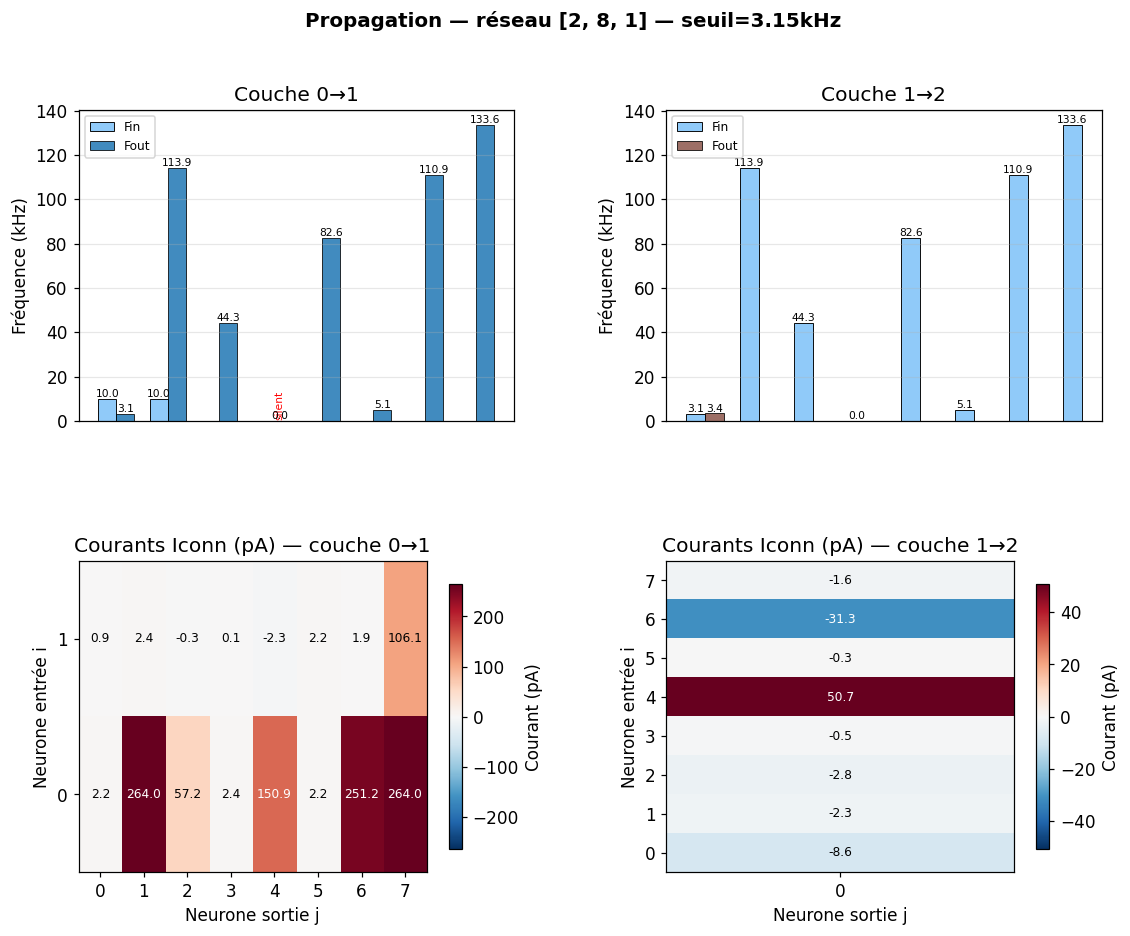

In [22]:
n_conn = len(layers_config)
fig = plt.figure(figsize=(5 * n_conn + 2, 9))
fig.suptitle(f'Propagation — réseau {layer_sizes} — seuil={THRESHOLD_HZ/1e3:.2f}kHz',
             fontsize=13, fontweight='bold')
gs = gridspec.GridSpec(2, n_conn, figure=fig, hspace=0.45, wspace=0.35)
colors = plt.cm.tab10(np.linspace(0, 0.5, n_conn))

for k in range(n_conn):
    Fin_k  = history_F[k]
    Fout_k = history_F[k + 1]
    Iconn  = history_Iconn[k]
    Itot   = history_Itot[k]
    N, M   = Iconn.shape
    color  = colors[k]

    # ── Haut : fréquences ──────────────────────────────────
    ax = fig.add_subplot(gs[0, k])
    x_in  = np.arange(N); x_out = np.arange(M); w = 0.35
    b1 = ax.bar(x_in  - w/2, Fin_k  * 1e-3, w, label='Fin',  color='#90CAF9', edgecolor='k', linewidth=0.6)
    b2 = ax.bar(x_out + w/2, Fout_k * 1e-3, w, label='Fout', color=color,     edgecolor='k', linewidth=0.6, alpha=0.85)
    # Marquer les neurones silencieux
    for j, (bar, f) in enumerate(zip(b2, Fout_k)):
        if f == 0:
            ax.text(bar.get_x()+bar.get_width()/2, 0.5, 'silent',
                    ha='center', va='bottom', fontsize=7, color='red', rotation=90)
    ax.set_title(f'Couche {k}→{k+1}')
    ax.set_ylabel('Fréquence (kHz)')
    ax.set_xticks([]); ax.legend(fontsize=8); ax.grid(True, axis='y', alpha=0.3)
    for bar, val in zip(b1, Fin_k*1e-3):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01, f'{val:.1f}',
                ha='center', va='bottom', fontsize=7)
    for bar, val in zip(b2, Fout_k*1e-3):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01, f'{val:.1f}',
                ha='center', va='bottom', fontsize=7)

    # ── Bas : matrice Iconn ────────────────────────────────
    ax = fig.add_subplot(gs[1, k])
    vmax = max(np.max(np.abs(Iconn)) * 1e12, 1e-3)
    im = ax.imshow(Iconn * 1e12, aspect='auto', origin='lower',
                   cmap='RdBu_r', vmin=-vmax, vmax=vmax)
    plt.colorbar(im, ax=ax, label='Courant (pA)', shrink=0.85)
    ax.set_xlabel('Neurone sortie j')
    ax.set_ylabel('Neurone entrée i')
    ax.set_title(f'Courants Iconn (pA) — couche {k}→{k+1}')
    ax.set_xticks(range(M)); ax.set_yticks(range(N))
    for i in range(N):
        for j in range(M):
            ax.text(j, i, f'{Iconn[i,j]*1e12:.1f}', ha='center', va='center',
                    fontsize=8, color='white' if abs(Iconn[i,j]*1e12) > vmax*0.5 else 'black')

plt.show()

## 8. Diagnostic Itot par couche

In [23]:
print('=' * 60)
print(f'  DIAGNOSTIC Itot — plage neurone [{NEURON_I_RHEOBASE*1e12:.1f}, {NEURON_I_MAX*1e12:.1f}] pA')
print('=' * 60)
for k, Itot in enumerate(history_Itot):
    for j, it in enumerate(Itot):
        if it < NEURON_I_RHEOBASE:
            statut = '→ SILENCIEUX (0 Hz)' if it >= 0 else f'→ NÉGATIF ({it*1e12:.1f} pA) SILENCIEUX'
        elif it > NEURON_I_MAX:
            statut = '→ SATURÉ (Fmax)'
        else:
            statut = '→ OK'
        print(f'  Couche {k}→{k+1}, neurone {j} : Itot={it*1e12:8.2f} pA  {statut}')
print('=' * 60)
print(f'  Fout finale = {history_F[-1][0]/1e3:.3f} kHz')
print(f'  Seuil       = {THRESHOLD_HZ/1e3:.3f} kHz')
print(f'  Décision    : Fout {"≥" if history_F[-1][0] >= THRESHOLD_HZ else "<"} seuil → classe {1 if history_F[-1][0] >= THRESHOLD_HZ else 0}')
print('=' * 60)

  DIAGNOSTIC Itot — plage neurone [3.0, 1000.0] pA
  Couche 0→1, neurone 0 : Itot=    3.05 pA  → OK
  Couche 0→1, neurone 1 : Itot=  266.42 pA  → OK
  Couche 0→1, neurone 2 : Itot=   56.95 pA  → OK
  Couche 0→1, neurone 3 : Itot=    2.57 pA  → SILENCIEUX (0 Hz)
  Couche 0→1, neurone 4 : Itot=  148.61 pA  → OK
  Couche 0→1, neurone 5 : Itot=    4.33 pA  → OK
  Couche 0→1, neurone 6 : Itot=  253.05 pA  → OK
  Couche 0→1, neurone 7 : Itot=  370.05 pA  → OK
  Couche 1→2, neurone 0 : Itot=    3.30 pA  → OK
  Fout finale = 3.409 kHz
  Seuil       = 3.151 kHz
  Décision    : Fout ≥ seuil → classe 1


## 9. Courbes de caractéristiques

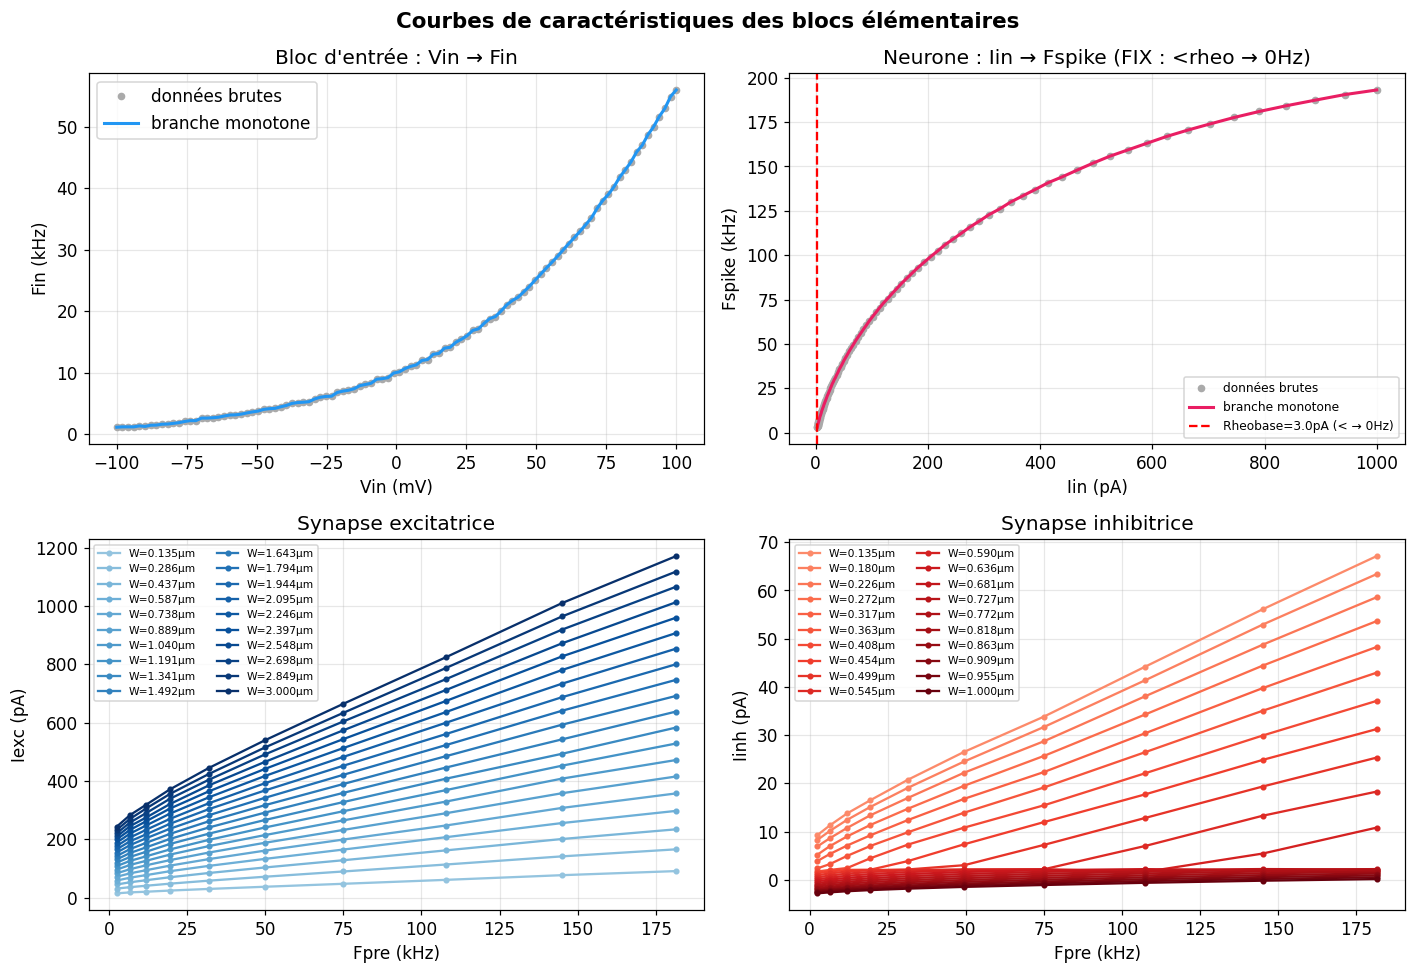

In [24]:
fig, axs = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle('Courbes de caractéristiques des blocs élémentaires', fontsize=14, fontweight='bold')

ax = axs[0, 0]
ax.plot(VEX_IN*1e3, FSPIKES_IN*1e-3, 'o', color='#aaa', ms=4, label='données brutes')
ax.plot(INPUT_V_AXIS*1e3, INPUT_F_AXIS*1e-3, '-', color='#2196F3', lw=2, label='branche monotone')
ax.set_xlabel('Vin (mV)'); ax.set_ylabel('Fin (kHz)')
ax.set_title("Bloc d'entrée : Vin → Fin")
ax.grid(True, alpha=0.3); ax.legend()

ax = axs[0, 1]
ax.plot(IEX_NEURO*1e12, FSPIKES_NEURO*1e-3, 'o', color='#aaa', ms=4, label='données brutes')
ax.plot(NEURON_I_AXIS*1e12, NEURON_F_AXIS*1e-3, '-', color='#E91E63', lw=2, label='branche monotone')
ax.axvline(NEURON_I_RHEOBASE*1e12, color='red', ls='--', lw=1.5,
           label=f'Rheobase={NEURON_I_RHEOBASE*1e12:.1f}pA (< → 0Hz)')
ax.set_xlabel('Iin (pA)'); ax.set_ylabel('Fspike (kHz)')
ax.set_title('Neurone : Iin → Fspike (FIX : <rheo → 0Hz)')
ax.grid(True, alpha=0.3); ax.legend(fontsize=8)

ax = axs[1, 0]
cmap_exc = plt.cm.Blues(np.linspace(0.4, 1.0, len(W_EXC_AXIS)))
for i, w in enumerate(W_EXC_AXIS):
    ax.plot(F_EXC_AXIS*1e-3, IPOST_EXC_GRID[i]*1e12, 'o-',
            color=cmap_exc[i], lw=1.5, ms=3, label=f'W={w:.3f}µm')
ax.set_xlabel('Fpre (kHz)'); ax.set_ylabel('Iexc (pA)')
ax.set_title('Synapse excitatrice')
ax.grid(True, alpha=0.3); ax.legend(fontsize=7, ncol=2)

ax = axs[1, 1]
cmap_inh = plt.cm.Reds(np.linspace(0.4, 1.0, len(W_INH_AXIS)))
for i, w in enumerate(W_INH_AXIS):
    ax.plot(F_INH_AXIS*1e-3, IPOST_INH_GRID[i]*1e12, 'o-',
            color=cmap_inh[i], lw=1.5, ms=3, label=f'W={w:.3f}µm')
ax.set_xlabel('Fpre (kHz)'); ax.set_ylabel('Iinh (pA)')
ax.set_title('Synapse inhibitrice')
ax.grid(True, alpha=0.3); ax.legend(fontsize=7, ncol=2)

plt.tight_layout(); plt.show()

## 10. Decision Map — espace [-1,1]²

**v8 :** décision par seuil sur la fréquence de sortie unique  
`Fout ≥ THRESHOLD_HZ → classe 1 (intérieur)`  
Confiance = `|Fout − seuil|` en kHz

Calcul decision map (50×50 = 2500 points)...
Terminé.


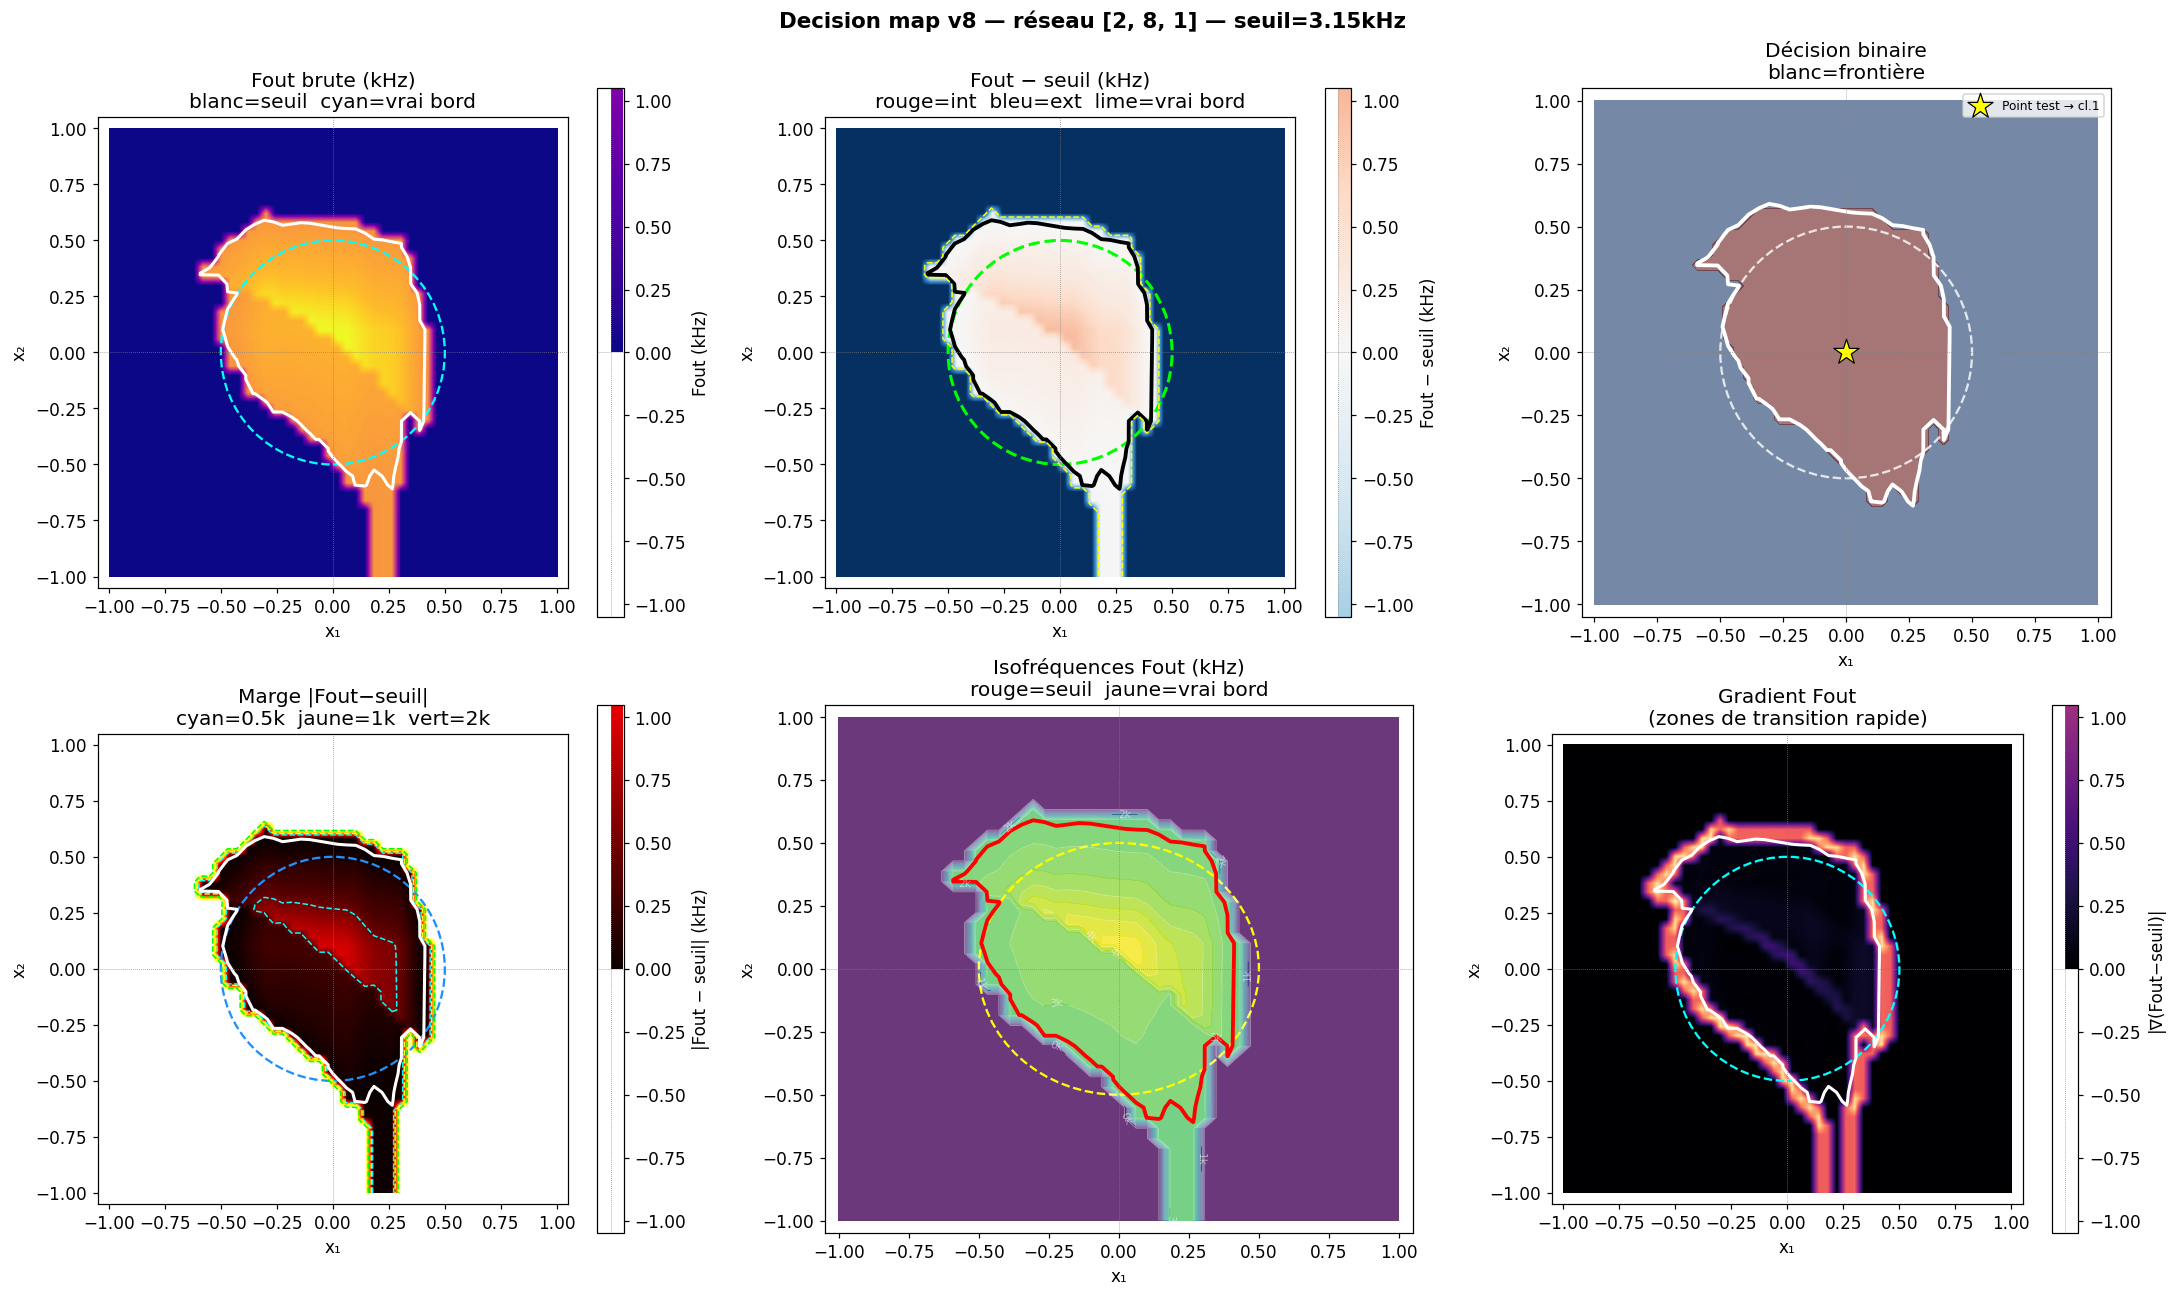


Surface prédite intérieur : 19.1%  (attendu ~19.6%)
Fout min=0.00kHz  max=4.12kHz  range=4.12kHz


In [25]:
N_GRID = 50   # résolution (augmenter pour plus de détails, mais plus lent)

x1_axis = np.linspace(-1, 1, N_GRID)
x2_axis = np.linspace(-1, 1, N_GRID)

fout_grid  = np.zeros((N_GRID, N_GRID))   # fréquence de sortie
class_grid = np.zeros((N_GRID, N_GRID), dtype=int)
conf_grid  = np.zeros((N_GRID, N_GRID))   # |Fout - seuil|
diff_grid  = np.zeros((N_GRID, N_GRID))   # Fout - seuil (signé)

print(f'Calcul decision map ({N_GRID}×{N_GRID} = {N_GRID**2} points)...')
for ii, x1 in enumerate(x1_axis):
    for jj, x2 in enumerate(x2_axis):
        Vin_loc = V_MIN + (np.array([x1, x2]) + 1.0) * (V_MAX - V_MIN) / 2.0
        F_loc   = np.array([input_f_of_v(v) for v in Vin_loc])
        for cfg in layers_config:
            F_loc, _, _ = layer_forward(F_loc,
                                         np.asarray(cfg['signs'],  int),
                                         np.asarray(cfg['widths'], float))
        fout   = float(F_loc[0])
        fout_grid [ii, jj] = fout
        class_grid[ii, jj] = 1 if fout >= THRESHOLD_HZ else 0
        diff_grid [ii, jj] = (fout - THRESHOLD_HZ) / 1e3   # kHz signé
        conf_grid [ii, jj] = abs(fout - THRESHOLD_HZ) / 1e3  # kHz absolu

print('Terminé.')

# ── Visualisation 6 cartes ────────────────────────────────────
vmax_diff = float(max(abs(diff_grid.min()), abs(diff_grid.max())))
norm_div  = TwoSlopeNorm(vmin=-vmax_diff, vcenter=0, vmax=vmax_diff)
DISK_RADIUS = 0.5

fig = plt.figure(figsize=(20, 12))
fig.suptitle(f'Decision map v8 — réseau {layer_sizes} — seuil={THRESHOLD_HZ/1e3:.2f}kHz',
             fontsize=14, fontweight='bold')

ext = [-1, 1, -1, 1]  # extent pour imshow

# ── 1. Fout brute ─────────────────────────────────────────────
ax = fig.add_subplot(2, 3, 1)
im = ax.imshow(fout_grid.T/1e3, origin='lower', extent=ext,
               aspect='equal', cmap='plasma', interpolation='bilinear')
plt.colorbar(im, ax=ax, label='Fout (kHz)')
ax.contour(x1_axis, x2_axis, diff_grid.T, levels=[0], colors='white', linewidths=2)
ax.add_patch(Circle((0,0), DISK_RADIUS, color='cyan', fill=False, lw=1.5, ls='--'))
ax.set_title('Fout brute (kHz)\nblanc=seuil  cyan=vrai bord')
ax.set_xlabel('x₁'); ax.set_ylabel('x₂')

# ── 2. Fout − seuil (divergente) ──────────────────────────────
ax = fig.add_subplot(2, 3, 2)
im = ax.imshow(diff_grid.T, origin='lower', extent=ext,
               aspect='equal', cmap='RdBu_r', norm=norm_div, interpolation='bilinear')
plt.colorbar(im, ax=ax, label='Fout − seuil (kHz)')
ax.contour(x1_axis, x2_axis, diff_grid.T, levels=[0], colors='black', linewidths=2.5)
ax.contour(x1_axis, x2_axis, diff_grid.T, levels=[-1, 1], colors='yellow',
           linewidths=1, linestyles='--')
ax.add_patch(Circle((0,0), DISK_RADIUS, color='lime', fill=False, lw=2, ls='--'))
ax.set_title('Fout − seuil (kHz)\nrouge=int  bleu=ext  lime=vrai bord')
ax.set_xlabel('x₁'); ax.set_ylabel('x₂')

# ── 3. Décision binaire ───────────────────────────────────────
ax = fig.add_subplot(2, 3, 3)
ax.contourf(x1_axis, x2_axis, class_grid.T,
            levels=[-0.5, 0.5, 1.5], colors=['#1a3a6b', '#6b1a1a'], alpha=0.6)
ax.contour(x1_axis, x2_axis, diff_grid.T, levels=[0], colors='white', linewidths=2.5)
ax.add_patch(Circle((0,0), DISK_RADIUS, color='white', fill=False, lw=1.5, ls='--', alpha=0.8))
ax.scatter(*XY_TEST, marker='*', s=300, color='yellow', edgecolors='black',
           linewidths=0.8, zorder=5, label=f'Point test → cl.{classe_pred}')
ax.legend(fontsize=8, loc='upper right')
ax.set_title(f'Décision binaire\nblanc=frontière')
ax.set_xlabel('x₁'); ax.set_ylabel('x₂'); ax.set_aspect('equal')

# ── 4. Marge |Fout − seuil| ───────────────────────────────────
ax = fig.add_subplot(2, 3, 4)
im = ax.imshow(conf_grid.T, origin='lower', extent=ext,
               aspect='equal', cmap='hot', interpolation='bilinear')
plt.colorbar(im, ax=ax, label='|Fout − seuil| (kHz)')
ax.contour(x1_axis, x2_axis, conf_grid.T, levels=[0.5, 1.0, 2.0],
           colors=['cyan', 'yellow', 'lime'], linewidths=1, linestyles='--')
ax.contour(x1_axis, x2_axis, diff_grid.T, levels=[0], colors='white', linewidths=2)
ax.add_patch(Circle((0,0), DISK_RADIUS, color='dodgerblue', fill=False, lw=1.5, ls='--'))
ax.set_title('Marge |Fout−seuil|\ncyan=0.5k  jaune=1k  vert=2k')
ax.set_xlabel('x₁'); ax.set_ylabel('x₂')

# ── 5. Isofréquences ──────────────────────────────────────────
ax = fig.add_subplot(2, 3, 5)
ax.contourf(x1_axis, x2_axis, fout_grid.T/1e3, levels=30, cmap='viridis', alpha=0.8)
cs = ax.contour(x1_axis, x2_axis, fout_grid.T/1e3, levels=15,
                colors='white', linewidths=0.5, alpha=0.5)
ax.clabel(cs, inline=True, fontsize=7, fmt='%.0fk')
ax.contour(x1_axis, x2_axis, diff_grid.T, levels=[0], colors='red', linewidths=2.5)
ax.add_patch(Circle((0,0), DISK_RADIUS, color='yellow', fill=False, lw=1.5, ls='--'))
ax.set_title('Isofréquences Fout (kHz)\nrouge=seuil  jaune=vrai bord')
ax.set_xlabel('x₁'); ax.set_ylabel('x₂')

# ── 6. Gradient (zones de transition rapide) ──────────────────
ax = fig.add_subplot(2, 3, 6)
dy, dx = np.gradient(diff_grid.T)
grad   = np.sqrt(dx**2 + dy**2)
im = ax.imshow(grad, origin='lower', extent=ext,
               aspect='equal', cmap='magma', interpolation='bilinear')
plt.colorbar(im, ax=ax, label='|∇(Fout−seuil)|')
ax.contour(x1_axis, x2_axis, diff_grid.T, levels=[0], colors='white', linewidths=2)
ax.add_patch(Circle((0,0), DISK_RADIUS, color='cyan', fill=False, lw=1.5, ls='--'))
ax.set_title('Gradient Fout\n(zones de transition rapide)')
ax.set_xlabel('x₁'); ax.set_ylabel('x₂')

for ax in fig.axes:
    ax.set_xlim(-1.05, 1.05); ax.set_ylim(-1.05, 1.05)
    ax.axhline(0, color='gray', lw=0.5, ls=':')
    ax.axvline(0, color='gray', lw=0.5, ls=':')

plt.tight_layout(); plt.show()

# Résumé
pct_int = 100 * class_grid.sum() / N_GRID**2
print(f'\nSurface prédite intérieur : {pct_int:.1f}%  (attendu ~{np.pi*DISK_RADIUS**2/4*100:.1f}%)')
print(f'Fout min={fout_grid.min()/1e3:.2f}kHz  max={fout_grid.max()/1e3:.2f}kHz  range={( fout_grid.max()-fout_grid.min())/1e3:.2f}kHz')

## 11. Tester plusieurs points

Cellule pratique pour tester des points spécifiques.

Calcul 50×50 points...
Terminé.


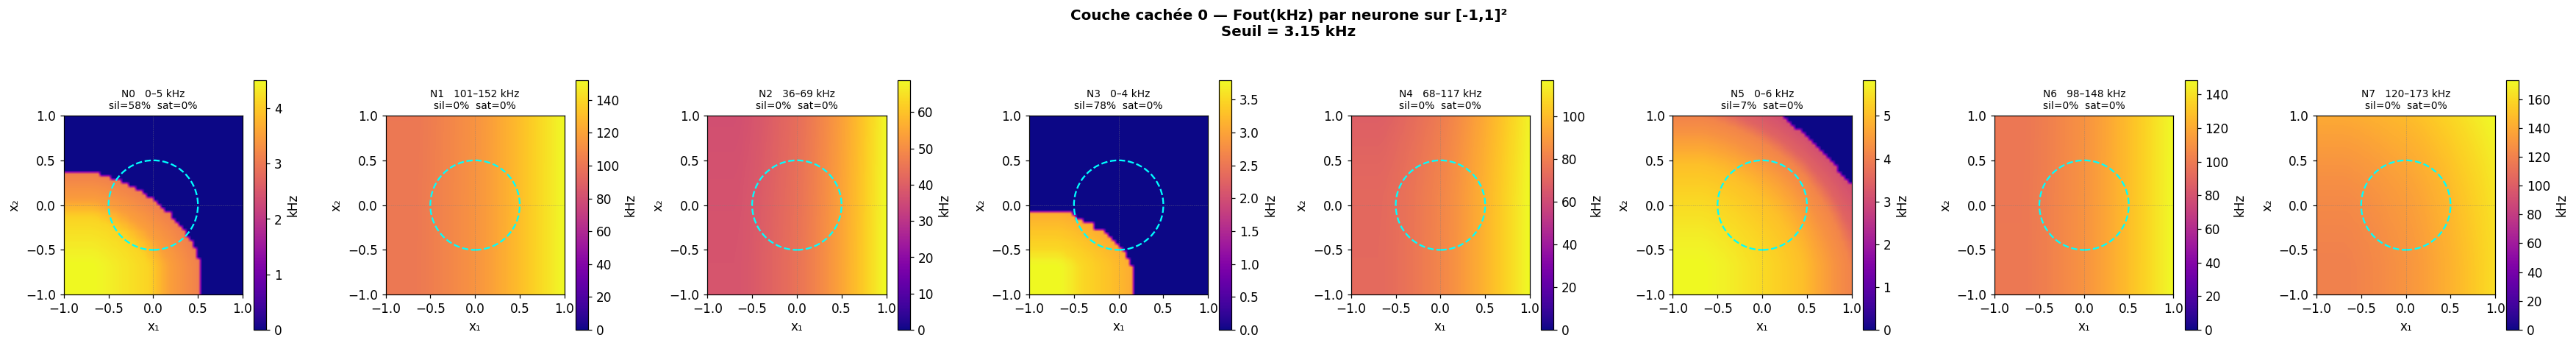

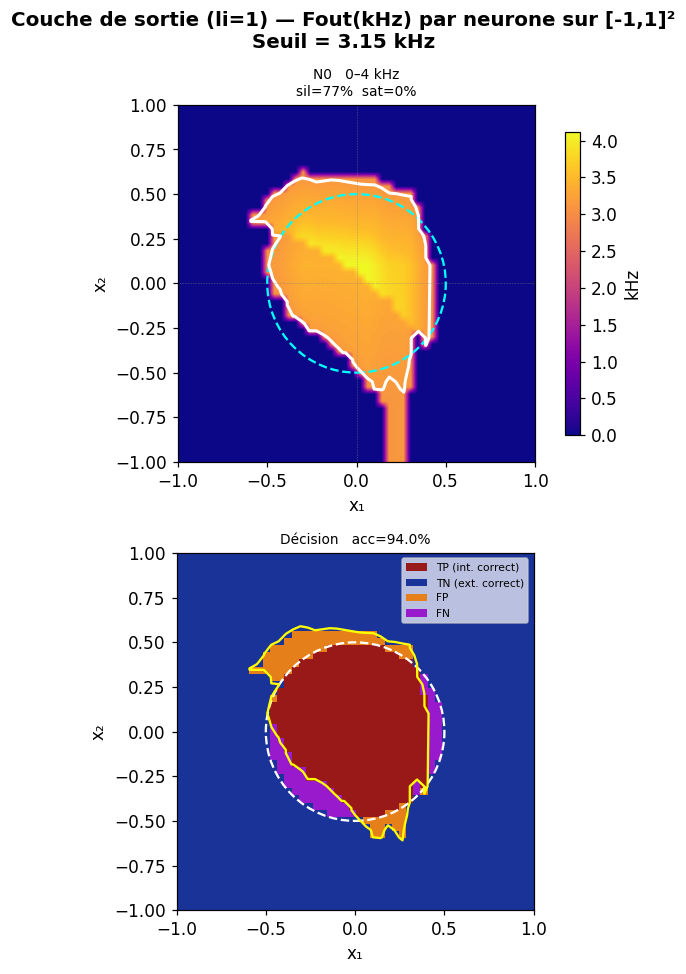

In [26]:
## 12. Decision maps par neurone — espace [-1,1]²

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Circle

N_GRID = 50  # résolution (50 = rapide, 100 = précis)

x1_axis = np.linspace(-1, 1, N_GRID)
x2_axis = np.linspace(-1, 1, N_GRID)

# ── Calcul des grilles par couche et par neurone ──────────────
# histo_grids[li][j] = grille (N_GRID, N_GRID) de Fout du neurone j, couche li
n_layers = len(layers_config)
histo_grids = []
for li, cfg in enumerate(layers_config):
    M = cfg['signs'].shape[1]
    grids = [np.zeros((N_GRID, N_GRID)) for _ in range(M)]
    histo_grids.append(grids)

print(f'Calcul {N_GRID}×{N_GRID} points...')
for ii, x1 in enumerate(x1_axis):
    for jj, x2 in enumerate(x2_axis):
        Vin_loc = V_MIN + (np.array([x1, x2]) + 1.0) * (V_MAX - V_MIN) / 2.0
        hF, _, _ = propagate(Vin_loc, layers_config)
        for li in range(n_layers):
            for j, fval in enumerate(hF[li + 1]):
                histo_grids[li][j][ii, jj] = fval / 1e3  # en kHz
print('Terminé.')

DISK_RADIUS = 0.5
ext = [-1, 1, -1, 1]

# ── Affichage par couche ──────────────────────────────────────
for li in range(n_layers):
    M = len(histo_grids[li])
    is_output = (li == n_layers - 1)
    
    # Nombre de lignes : 1 ligne fréquence + 1 ligne décision si couche de sortie
    n_rows = 2 if is_output else 1
    fig, axes = plt.subplots(n_rows, M,
                              figsize=(max(4 * M, 6), 4.5 * n_rows),
                              squeeze=False)
    
    layer_label = f'Couche de sortie (li={li})' if is_output else f'Couche cachée {li}'
    fig.suptitle(f'{layer_label} — Fout(kHz) par neurone sur [-1,1]²\n'
                 f'Seuil = {THRESHOLD_HZ/1e3:.2f} kHz',
                 fontsize=13, fontweight='bold')

    for j in range(M):
        grid = histo_grids[li][j]

        # ── Ligne 0 : heatmap fréquence ──────────────────────
        ax = axes[0, j]
        vmax = max(grid.max(), 0.01)
        im = ax.imshow(grid.T, origin='lower', extent=ext,
                       aspect='equal', cmap='plasma',
                       vmin=0, vmax=vmax, interpolation='bilinear')
        plt.colorbar(im, ax=ax, label='kHz', shrink=0.85)

        # Contour seuil (couche de sortie uniquement)
        if is_output:
            ax.contour(x1_axis, x2_axis, (grid - THRESHOLD_HZ/1e3).T,
                       levels=[0], colors='white', linewidths=2)

        # Vrai bord du disque
        ax.add_patch(Circle((0, 0), DISK_RADIUS,
                             color='cyan', fill=False, lw=1.5, ls='--'))

        # Stats
        silent_pct = np.sum(grid == 0) / grid.size * 100
        sat_pct    = np.sum(grid * 1e3 >= NEURON_F_MAX * 0.99) / grid.size * 100
        ax.set_title(f'N{j}   {grid.min():.0f}–{grid.max():.0f} kHz\n'
                     f'sil={silent_pct:.0f}%  sat={sat_pct:.0f}%', fontsize=9)
        ax.set_xlabel('x₁'); ax.set_ylabel('x₂')
        ax.axhline(0, color='gray', lw=0.4, ls=':')
        ax.axvline(0, color='gray', lw=0.4, ls=':')

        # ── Ligne 1 (sortie seulement) : carte de décision ───
        if is_output:
            ax2 = axes[1, j]
            pred_grid = (grid >= THRESHOLD_HZ / 1e3).astype(int)

            X1, X2 = np.meshgrid(x1_axis, x2_axis, indexing='ij')
            true_grid = ((X1**2 + X2**2) < DISK_RADIUS**2).astype(int)

            # Couleurs : vert=correct, rouge=erreur
            correct   = (pred_grid == true_grid)
            rgb = np.zeros((*grid.shape, 3))
            # intérieur prédit correct (TP) → rouge foncé
            rgb[( pred_grid==1) & correct]  = [0.6, 0.1, 0.1]
            # extérieur prédit correct (TN) → bleu foncé
            rgb[( pred_grid==0) & correct]  = [0.1, 0.2, 0.6]
            # FP (prédit int, vrai ext)     → orange
            rgb[( pred_grid==1) & ~correct] = [0.9, 0.5, 0.1]
            # FN (prédit ext, vrai int)     → violet
            rgb[( pred_grid==0) & ~correct] = [0.6, 0.1, 0.8]

            ax2.imshow(rgb.transpose(1, 0, 2), origin='lower',
                       extent=ext, aspect='equal', interpolation='nearest')
            ax2.add_patch(Circle((0, 0), DISK_RADIUS,
                                  color='white', fill=False, lw=1.5, ls='--'))
            ax2.contour(x1_axis, x2_axis, (grid - THRESHOLD_HZ/1e3).T,
                        levels=[0], colors='yellow', linewidths=1.5)

            acc = correct.mean() * 100
            ax2.set_title(f'Décision   acc={acc:.1f}%', fontsize=9)
            ax2.set_xlabel('x₁'); ax2.set_ylabel('x₂')

            from matplotlib.patches import Patch
            legend_els = [
                Patch(facecolor=[0.6,0.1,0.1], label='TP (int. correct)'),
                Patch(facecolor=[0.1,0.2,0.6], label='TN (ext. correct)'),
                Patch(facecolor=[0.9,0.5,0.1], label='FP'),
                Patch(facecolor=[0.6,0.1,0.8], label='FN'),
            ]
            ax2.legend(handles=legend_els, fontsize=7,
                       loc='upper right', framealpha=0.7)

    plt.tight_layout()
    plt.show()
    print()

Architecture détectée : [2, 8, 1]
25 points construits.
Propagation hybride [2,8,1]...

  Pt        Vin1    Vin2  Fmod(kHz)  Fhyb(kHz)    ΔFout  Décision
  C0_0     -100mV   -100mV       0.00       0.00    +0.00  ✓ accord
  C0_1      -50mV   -100mV       0.00       0.00    +0.00  ✓ accord
  C0_2        0mV   -100mV       0.00       0.00    +0.00  ✓ accord
  C0_3       50mV   -100mV       0.00       0.00    +0.00  ✓ accord
  C0_4      100mV   -100mV       0.00       0.00    +0.00  ✓ accord
  C0_5     -100mV    -50mV       0.00       0.00    +0.00  ✓ accord
  C0_6      -50mV    -50mV       0.00       0.00    +0.00  ✓ accord
  C0_7        0mV    -50mV       3.08       0.00    -3.08  ✓ accord
  C0_8       50mV    -50mV       0.00       0.00    +0.00  ✓ accord
  C0_9      100mV    -50mV       0.00       0.00    +0.00  ✓ accord
  C0_10    -100mV      0mV       0.00       0.00    +0.00  ✓ accord
  C0_11     -50mV      0mV       0.00       0.00    +0.00  ✓ accord
  C0_12       0mV      0mV    

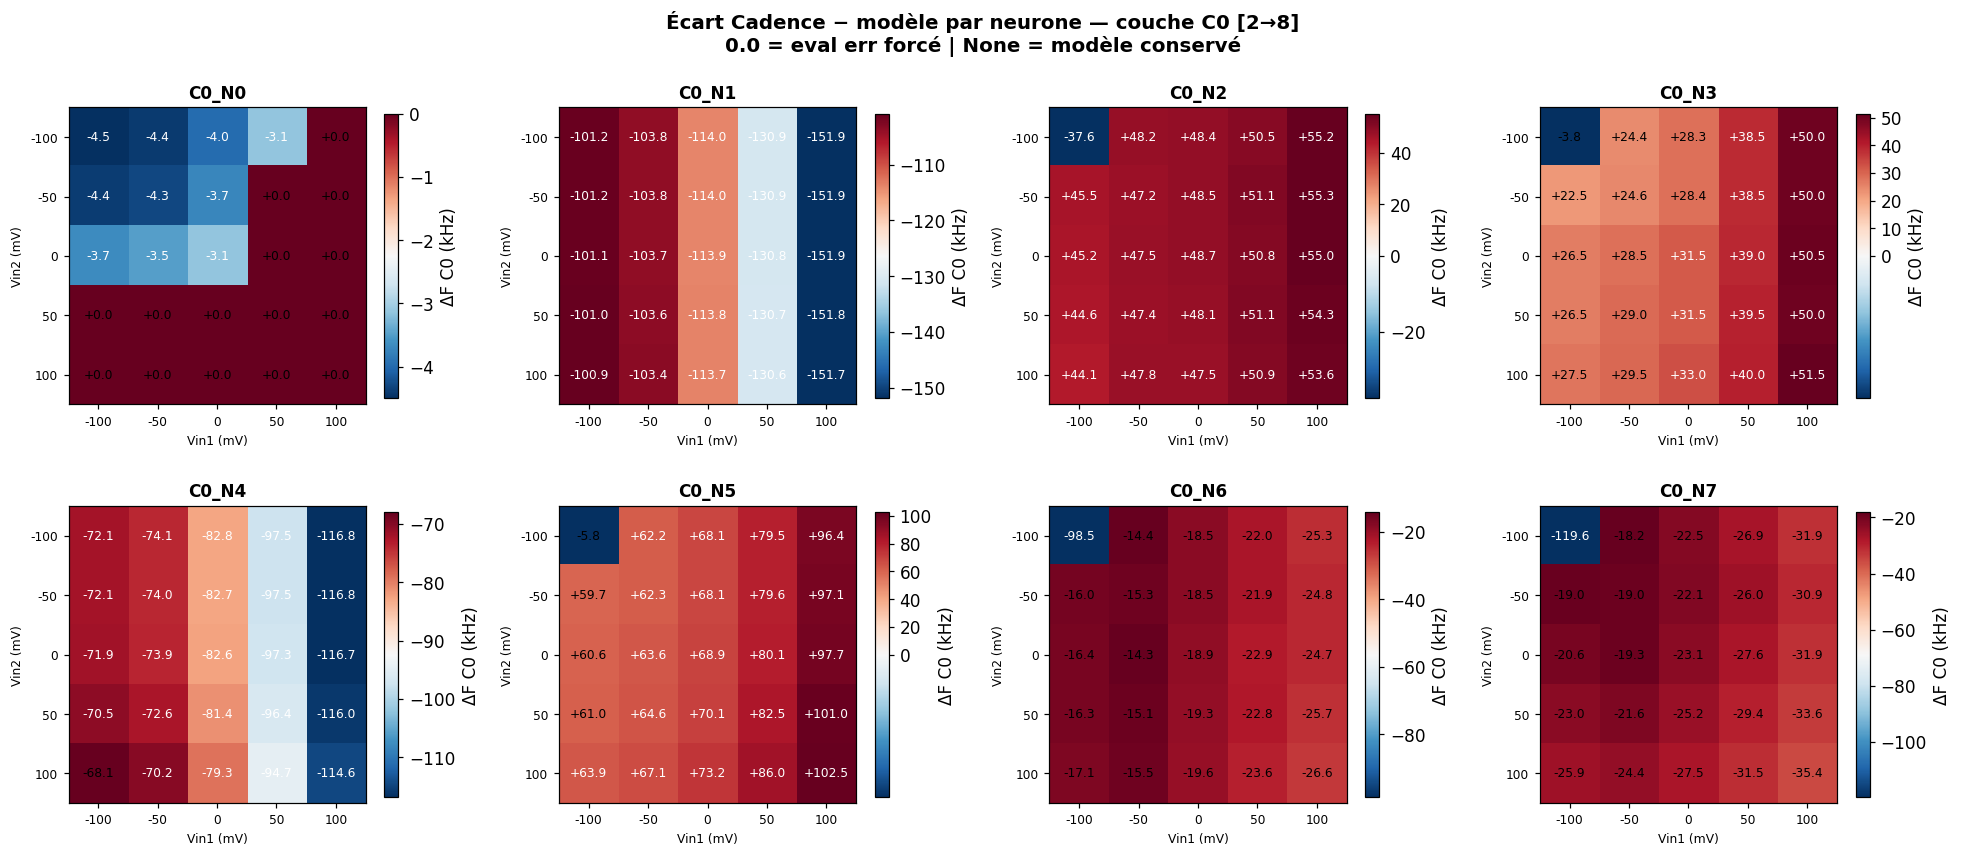

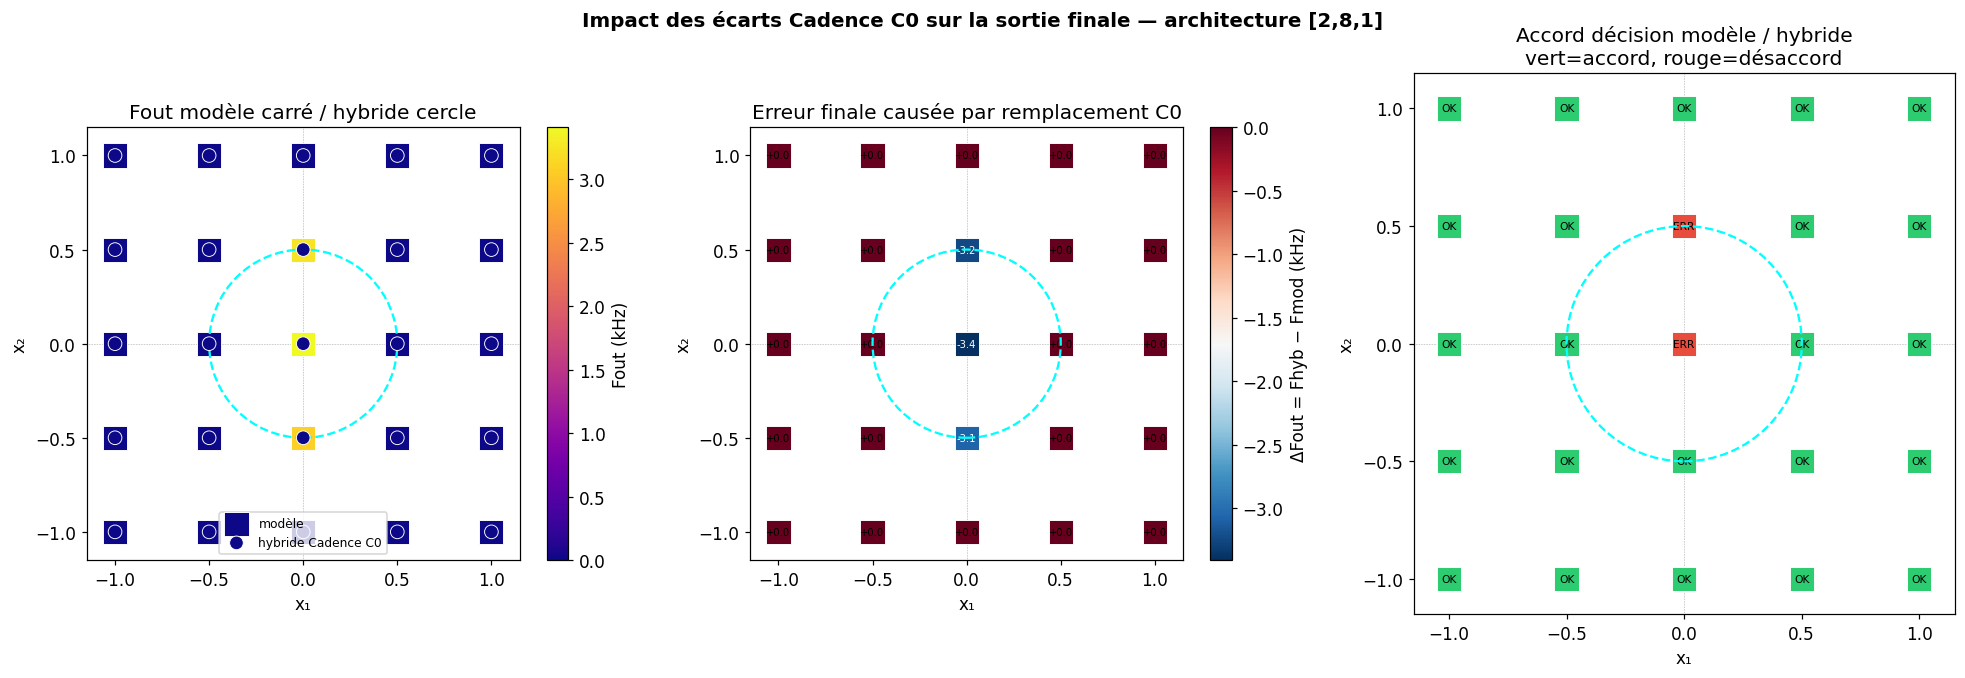

In [27]:
## 13. Propagation hybride Cadence → déformation sortie
##     Architecture [2, 8, 1] — grille 5×5 couche C0 uniquement

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from matplotlib.colors import TwoSlopeNorm

# ══════════════════════════════════════════════════════════════
# DÉTECTION AUTOMATIQUE DE L'ARCHITECTURE
# ══════════════════════════════════════════════════════════════

N_HIDDEN_LAYERS = len(layers_config) - 1
HIDDEN_SIZES = [
    layers_config[li]['signs'].shape[1]
    for li in range(N_HIDDEN_LAYERS)
]
OUT_SIZE = layers_config[-1]['signs'].shape[1]

print(f'Architecture détectée : [2, {", ".join(map(str, HIDDEN_SIZES))}, {OUT_SIZE}]')

assert HIDDEN_SIZES == [8], "Ce bloc est prévu pour une architecture [2, 8, 1]"
assert OUT_SIZE == 1, "La sortie doit être unique : architecture [2, 8, 1]"

# ══════════════════════════════════════════════════════════════
# GRILLE DE TENSIONS CADENCE
# ══════════════════════════════════════════════════════════════

VIN_GRID = [-0.100, -0.050, 0.000, 0.050, 0.100]  # Volts

def vin_to_xy(vin):
    return 2.0 * (vin - V_MIN) / (V_MAX - V_MIN) - 1.0

# ══════════════════════════════════════════════════════════════
# MESURES CADENCE — COUCHE C0 SEULEMENT
# Chaque point = [N0, N1, N2, N3, N4, N5, N6, N7] en Hz
# 0.0  = eval err / neurone silencieux mesuré
# None = non mesuré → valeur modèle utilisée
# ══════════════════════════════════════════════════════════════

# ── COUCHE C0 — 25 points grille 5×5 ─────────────────────────
#                   N0      N1      N2       N3      N4      N5      N6       N7

# ── COUCHE C0 — 25 points grille 5×5 ─────────────────────────
# eval err = 0.0
#                   N0      N1      N2       N3      N4      N5       N6       N7

C0_0  = [0.0, 0.0,   0.0,    0.0, 0.0,    0.0,   0.0,    0.0   ]  # Vin1=-100  Vin2=-100
C0_1  = [0.0, 0.0,  87.0e3, 28.0e3, 0.0,  68.0e3, 86.5e3,103.5e3]  # Vin1= -50  Vin2=-100
C0_2  = [0.0, 0.0,  93.0e3, 31.5e3, 0.0,  73.5e3, 92.5e3,107.5e3]  # Vin1=   0  Vin2=-100
C0_3  = [0.0, 0.0, 105.0e3, 38.5e3, 0.0,  84.5e3,105.5e3,116.5e3]  # Vin1=  50  Vin2=-100
C0_4  = [0.0, 0.0, 124.0e3, 50.0e3, 0.0, 100.5e3,123.0e3,129.5e3]  # Vin1= 100  Vin2=-100

C0_5  = [0.0, 0.0,  83.0e3, 26.0e3, 0.0,  65.5e3, 82.5e3,101.5e3]  # Vin1=-100  Vin2= -50
C0_6  = [0.0, 0.0,  86.0e3, 28.0e3, 0.0,  68.0e3, 85.5e3,103.5e3]  # Vin1= -50  Vin2= -50
C0_7  = [0.0, 0.0,  93.0e3, 31.5e3, 0.0,  73.5e3, 92.5e3,108.5e3]  # Vin1=   0  Vin2= -50
C0_8  = [0.0, 0.0, 105.5e3, 38.5e3, 0.0,  84.5e3,105.5e3,118.0e3]  # Vin1=  50  Vin2= -50
C0_9  = [0.0, 0.0, 124.0e3, 50.0e3, 0.0, 101.0e3,123.5e3,131.0e3]  # Vin1= 100  Vin2= -50

C0_10 = [0.0, 0.0,  82.5e3, 26.5e3, 0.0,  66.0e3, 82.0e3,103.5e3]  # Vin1=-100  Vin2=   0
C0_11 = [0.0, 0.0,  86.0e3, 28.5e3, 0.0,  69.0e3, 86.5e3,106.5e3]  # Vin1= -50  Vin2=   0
C0_12 = [0.0, 0.0,  93.0e3, 31.5e3, 0.0,  74.0e3, 92.0e3,110.5e3]  # Vin1=   0  Vin2=   0
C0_13 = [0.0, 0.0, 105.0e3, 39.0e3, 0.0,  84.5e3,104.5e3,119.0e3]  # Vin1=  50  Vin2=   0
C0_14 = [0.0, 0.0, 123.5e3, 50.5e3, 0.0, 101.0e3,123.5e3,132.0e3]  # Vin1= 100  Vin2=   0

C0_15 = [0.0, 0.0,  81.5e3, 26.5e3, 0.0,  66.0e3, 82.0e3,107.5e3]  # Vin1=-100  Vin2=  50
C0_16 = [0.0, 0.0,  85.5e3, 29.0e3, 0.0,  69.5e3, 85.5e3,110.5e3]  # Vin1= -50  Vin2=  50
C0_17 = [0.0, 0.0,  92.0e3, 31.5e3, 0.0,  74.5e3, 91.5e3,114.0e3]  # Vin1=   0  Vin2=  50
C0_18 = [0.0, 0.0, 105.0e3, 39.5e3, 0.0,  86.0e3,104.5e3,122.0e3]  # Vin1=  50  Vin2=  50
C0_19 = [0.0, 0.0, 122.5e3, 50.0e3, 0.0, 101.0e3,122.5e3,134.0e3]  # Vin1= 100  Vin2=  50

C0_20 = [0.0, 0.0,  80.5e3, 27.5e3, 0.0,  68.0e3, 81.0e3,114.0e3]  # Vin1=-100  Vin2= 100
C0_21 = [0.0, 0.0,  85.5e3, 29.5e3, 0.0,  71.0e3, 85.0e3,117.0e3]  # Vin1= -50  Vin2= 100
C0_22 = [0.0, 0.0,  91.0e3, 33.0e3, 0.0,  76.5e3, 91.0e3,120.0e3]  # Vin1=   0  Vin2= 100
C0_23 = [0.0, 0.0, 104.5e3, 40.0e3, 0.0,  86.0e3,103.5e3,127.0e3]  # Vin1=  50  Vin2= 100
C0_24 = [0.0, 0.0, 121.5e3, 51.5e3, 0.0, 102.5e3,121.5e3,137.5e3]  # Vin1= 100  Vin2= 100

_cad_c0 = [
    C0_0, C0_1, C0_2, C0_3, C0_4,
    C0_5, C0_6, C0_7, C0_8, C0_9,
    C0_10, C0_11, C0_12, C0_13, C0_14,
    C0_15, C0_16, C0_17, C0_18, C0_19,
    C0_20, C0_21, C0_22, C0_23, C0_24
]

# ══════════════════════════════════════════════════════════════
# CONSTRUCTION DES 25 POINTS
# ══════════════════════════════════════════════════════════════

GRID_POINTS = []
idx = 0

for vin2 in VIN_GRID:
    for vin1 in VIN_GRID:
        GRID_POINTS.append({
            'name': f'C0_{idx}',
            'vin1': vin1,
            'vin2': vin2,
            'x1': vin_to_xy(vin1),
            'x2': vin_to_xy(vin2),
            'cad_c0': _cad_c0[idx],
        })
        idx += 1

print(f'{len(GRID_POINTS)} points construits.')

# ══════════════════════════════════════════════════════════════
# PROPAGATION HYBRIDE POUR [2,8,1]
# On remplace seulement la couche cachée C0 par les mesures Cadence.
# Ensuite on propage vers la sortie unique.
# ══════════════════════════════════════════════════════════════

def propagate_hybrid_281(Vin_V, layers_config, cad_c0):
    """
    Propagation hybride pour architecture [2,8,1].

    Étape 1 : modèle Python pour obtenir Fin et C0 modèle.
    Étape 2 : remplacement de C0 par les valeurs Cadence mesurées.
    Étape 3 : propagation C0 Cadence -> sortie.
    """

    hF_model, _, _ = propagate(Vin_V, layers_config)

    Fin_model = hF_model[0].copy()
    C0_model = hF_model[1].copy()
    Fout_model = float(hF_model[-1][0])

    C0_hybrid = C0_model.copy()

    for j, cad_val in enumerate(cad_c0):
        if cad_val is not None:
            C0_hybrid[j] = float(cad_val)

    cfg_out = layers_config[1]   # couche 8 -> 1

    Fout_hybrid_vec, _, _ = layer_forward(
        C0_hybrid,
        np.asarray(cfg_out['signs'], int),
        np.asarray(cfg_out['widths'], float)
    )

    Fout_hybrid = float(Fout_hybrid_vec[0])

    hF_hybrid = [
        Fin_model,
        C0_hybrid,
        np.array([Fout_hybrid])
    ]

    return Fout_model, Fout_hybrid, hF_model, hF_hybrid


# ══════════════════════════════════════════════════════════════
# CALCUL SUR LES 25 POINTS
# ══════════════════════════════════════════════════════════════

print('Propagation hybride [2,8,1]...')

for pt in GRID_POINTS:
    Vin = np.array([pt['vin1'], pt['vin2']])

    fmod, fhyb, hF_mod, hF_hyb = propagate_hybrid_281(
        Vin,
        layers_config,
        pt['cad_c0']
    )

    pt['fmod'] = fmod
    pt['fhyb'] = fhyb
    pt['ecart_fout'] = (fhyb - fmod) / 1e3
    pt['hF_mod'] = hF_mod
    pt['hF_hyb'] = hF_hyb

    pt['dec_mod'] = int(fmod >= THRESHOLD_HZ)
    pt['dec_hyb'] = int(fhyb >= THRESHOLD_HZ)
    pt['agree'] = pt['dec_mod'] == pt['dec_hyb']

    pt['ecart_c0'] = [
        (float(c) - hF_mod[1][j]) / 1e3 if c is not None else None
        for j, c in enumerate(pt['cad_c0'])
    ]


# ══════════════════════════════════════════════════════════════
# TABLEAU RÉCAPITULATIF
# ══════════════════════════════════════════════════════════════

print('\n' + '=' * 82)
print(f'  {"Pt":<6} {"Vin1":>7} {"Vin2":>7} '
      f'{"Fmod(kHz)":>10} {"Fhyb(kHz)":>10} {"ΔFout":>8}  Décision')
print('=' * 82)

for pt in GRID_POINTS:
    flag = '✓ accord' if pt['agree'] else '✗ désaccord'
    print(f'  {pt["name"]:<6} '
          f'{pt["vin1"]*1e3:>6.0f}mV '
          f'{pt["vin2"]*1e3:>6.0f}mV '
          f'{pt["fmod"]/1e3:>10.2f} '
          f'{pt["fhyb"]/1e3:>10.2f} '
          f'{pt["ecart_fout"]:>+8.2f}  '
          f'{flag}')

print('=' * 82)

ef_all = np.array([pt['ecart_fout'] for pt in GRID_POINTS])

print(f'  MAE  = {np.mean(np.abs(ef_all)):.3f} kHz')
print(f'  RMSE = {np.sqrt(np.mean(ef_all**2)):.3f} kHz')
print(f'  Désaccords décision : {sum(1 for p in GRID_POINTS if not p["agree"])}/{len(GRID_POINTS)}')
print('=' * 82)


# ══════════════════════════════════════════════════════════════
# OUTILS DE NORMALISATION
# ══════════════════════════════════════════════════════════════

def safe_norm(values, vcenter=0.0):
    arr = np.asarray(values, dtype=float)
    arr = arr[np.isfinite(arr)]

    if arr.size == 0:
        return plt.Normalize(vmin=-1, vmax=1)

    vmin = float(np.nanmin(arr))
    vmax = float(np.nanmax(arr))

    if vmin == vmax:
        return plt.Normalize(vmin=vmin - 1, vmax=vmax + 1)

    if vmin < vcenter < vmax:
        return TwoSlopeNorm(vmin=vmin, vcenter=vcenter, vmax=vmax)

    return plt.Normalize(vmin=vmin, vmax=vmax)


# ══════════════════════════════════════════════════════════════
# FIGURE 1 — ÉCART CADENCE − MODÈLE SUR C0
# ══════════════════════════════════════════════════════════════

fig1, axes1 = plt.subplots(2, 4, figsize=(18, 8))
fig1.suptitle(
    'Écart Cadence − modèle par neurone — couche C0 [2→8]\n'
    '0.0 = eval err forcé | None = modèle conservé',
    fontsize=13,
    fontweight='bold'
)

for j in range(8):
    ax = axes1[j // 4, j % 4]

    mat = np.full((5, 5), np.nan)

    for idx_pt, pt in enumerate(GRID_POINTS):
        r = idx_pt // 5
        c = idx_pt % 5
        ec = pt['ecart_c0'][j]
        if ec is not None:
            mat[r, c] = ec

    norm_j = safe_norm(mat, vcenter=0.0)

    im = ax.imshow(
        mat,
        cmap='RdBu_r',
        norm=norm_j,
        origin='upper',
        aspect='equal',
        interpolation='nearest'
    )

    plt.colorbar(im, ax=ax, label='ΔF C0 (kHz)', shrink=0.8)

    vmax_txt = np.nanmax(np.abs(mat)) if np.any(np.isfinite(mat)) else 1.0

    for r in range(5):
        for c in range(5):
            if np.isnan(mat[r, c]):
                ax.text(c, r, 'mod', ha='center', va='center',
                        fontsize=8, color='gray')
            else:
                ax.text(
                    c, r,
                    f'{mat[r, c]:+.1f}',
                    ha='center',
                    va='center',
                    fontsize=8,
                    color='white' if abs(mat[r, c]) > 0.6 * vmax_txt else 'black'
                )

    ax.set_xticks(range(5))
    ax.set_yticks(range(5))
    ax.set_xticklabels([f'{int(v * 1e3)}' for v in VIN_GRID], fontsize=8)
    ax.set_yticklabels([f'{int(v * 1e3)}' for v in VIN_GRID], fontsize=8)

    ax.set_xlabel('Vin1 (mV)', fontsize=8)
    ax.set_ylabel('Vin2 (mV)', fontsize=8)
    ax.set_title(f'C0_N{j}', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()


# ══════════════════════════════════════════════════════════════
# FIGURE 2 — IMPACT SUR LA SORTIE UNIQUE
# ══════════════════════════════════════════════════════════════

DISK_R = 0.5

N_CONT = 50
x1c = np.linspace(-1, 1, N_CONT)
x2c = np.linspace(-1, 1, N_CONT)

fout_cont = np.zeros((N_CONT, N_CONT))

for ii, x2 in enumerate(x2c):
    for jj, x1 in enumerate(x1c):
        Vc = V_MIN + (np.array([x1, x2]) + 1.0) * (V_MAX - V_MIN) / 2.0
        hFc, _, _ = propagate(Vc, layers_config)
        fout_cont[ii, jj] = hFc[-1][0] / 1e3

X1_PTS = np.array([pt['x1'] for pt in GRID_POINTS])
X2_PTS = np.array([pt['x2'] for pt in GRID_POINTS])
FMOD = np.array([pt['fmod'] / 1e3 for pt in GRID_POINTS])
FHYB = np.array([pt['fhyb'] / 1e3 for pt in GRID_POINTS])
EFOUT = np.array([pt['ecart_fout'] for pt in GRID_POINTS])
AGREE = np.array([pt['agree'] for pt in GRID_POINTS])

fig2, axes2 = plt.subplots(1, 3, figsize=(18, 6))
fig2.suptitle(
    'Impact des écarts Cadence C0 sur la sortie finale — architecture [2,8,1]',
    fontsize=13,
    fontweight='bold'
)

def add_decor(ax):
    ax.add_patch(
        Circle((0, 0), DISK_R, color='cyan', fill=False,
               lw=1.5, ls='--', zorder=4)
    )

    ax.contour(
        x1c,
        x2c,
        fout_cont,
        levels=[THRESHOLD_HZ / 1e3],
        colors='white',
        linewidths=1.5,
        linestyles='--'
    )

    ax.axhline(0, color='gray', lw=0.4, ls=':')
    ax.axvline(0, color='gray', lw=0.4, ls=':')
    ax.set_xlim(-1.15, 1.15)
    ax.set_ylim(-1.15, 1.15)
    ax.set_aspect('equal')
    ax.set_xlabel('x₁')
    ax.set_ylabel('x₂')


# 2a. Fout modèle vs hybride
ax = axes2[0]

sc1 = ax.scatter(
    X1_PTS,
    X2_PTS,
    c=FMOD,
    cmap='plasma',
    s=250,
    marker='s',
    edgecolors='white',
    linewidths=0.6,
    vmin=0,
    zorder=3,
    label='modèle'
)

sc2 = ax.scatter(
    X1_PTS,
    X2_PTS,
    c=FHYB,
    cmap='plasma',
    s=80,
    marker='o',
    edgecolors='white',
    linewidths=0.6,
    vmin=0,
    zorder=5,
    label='hybride Cadence C0'
)

plt.colorbar(sc1, ax=ax, label='Fout (kHz)', shrink=0.8)
add_decor(ax)
ax.set_title('Fout modèle carré / hybride cercle')
ax.legend(fontsize=8)


# 2b. ΔFout
ax = axes2[1]

norm = safe_norm(EFOUT, vcenter=0.0)

sc = ax.scatter(
    X1_PTS,
    X2_PTS,
    c=EFOUT,
    cmap='RdBu_r',
    norm=norm,
    s=250,
    marker='s',
    edgecolors='white',
    linewidths=0.6,
    zorder=3
)

plt.colorbar(sc, ax=ax, label='ΔFout = Fhyb − Fmod (kHz)', shrink=0.8)

vmax_txt = np.max(np.abs(EFOUT)) if EFOUT.size else 1.0

for pt in GRID_POINTS:
    ax.text(
        pt['x1'],
        pt['x2'],
        f'{pt["ecart_fout"]:+.1f}',
        ha='center',
        va='center',
        fontsize=6.5,
        color='white' if abs(pt['ecart_fout']) > 0.6 * vmax_txt else 'black'
    )

add_decor(ax)
ax.set_title('Erreur finale causée par remplacement C0')


# 2c. Accord décision modèle / hybride
ax = axes2[2]

colors_dec = ['#2ecc71' if a else '#e74c3c' for a in AGREE]

ax.scatter(
    X1_PTS,
    X2_PTS,
    c=colors_dec,
    s=250,
    marker='s',
    edgecolors='white',
    linewidths=0.6,
    zorder=3
)

for pt in GRID_POINTS:
    txt = 'OK' if pt['agree'] else 'ERR'
    ax.text(
        pt['x1'],
        pt['x2'],
        txt,
        ha='center',
        va='center',
        fontsize=7,
        color='black'
    )

add_decor(ax)
ax.set_title('Accord décision modèle / hybride\nvert=accord, rouge=désaccord')

plt.tight_layout()
plt.show()

Construction des interpolateurs RBF par neurone...
  C0 : 8/8 neurones avec RBF Cadence
  C0 mesurée : True

Calcul grille Cadence correct...
Terminé.


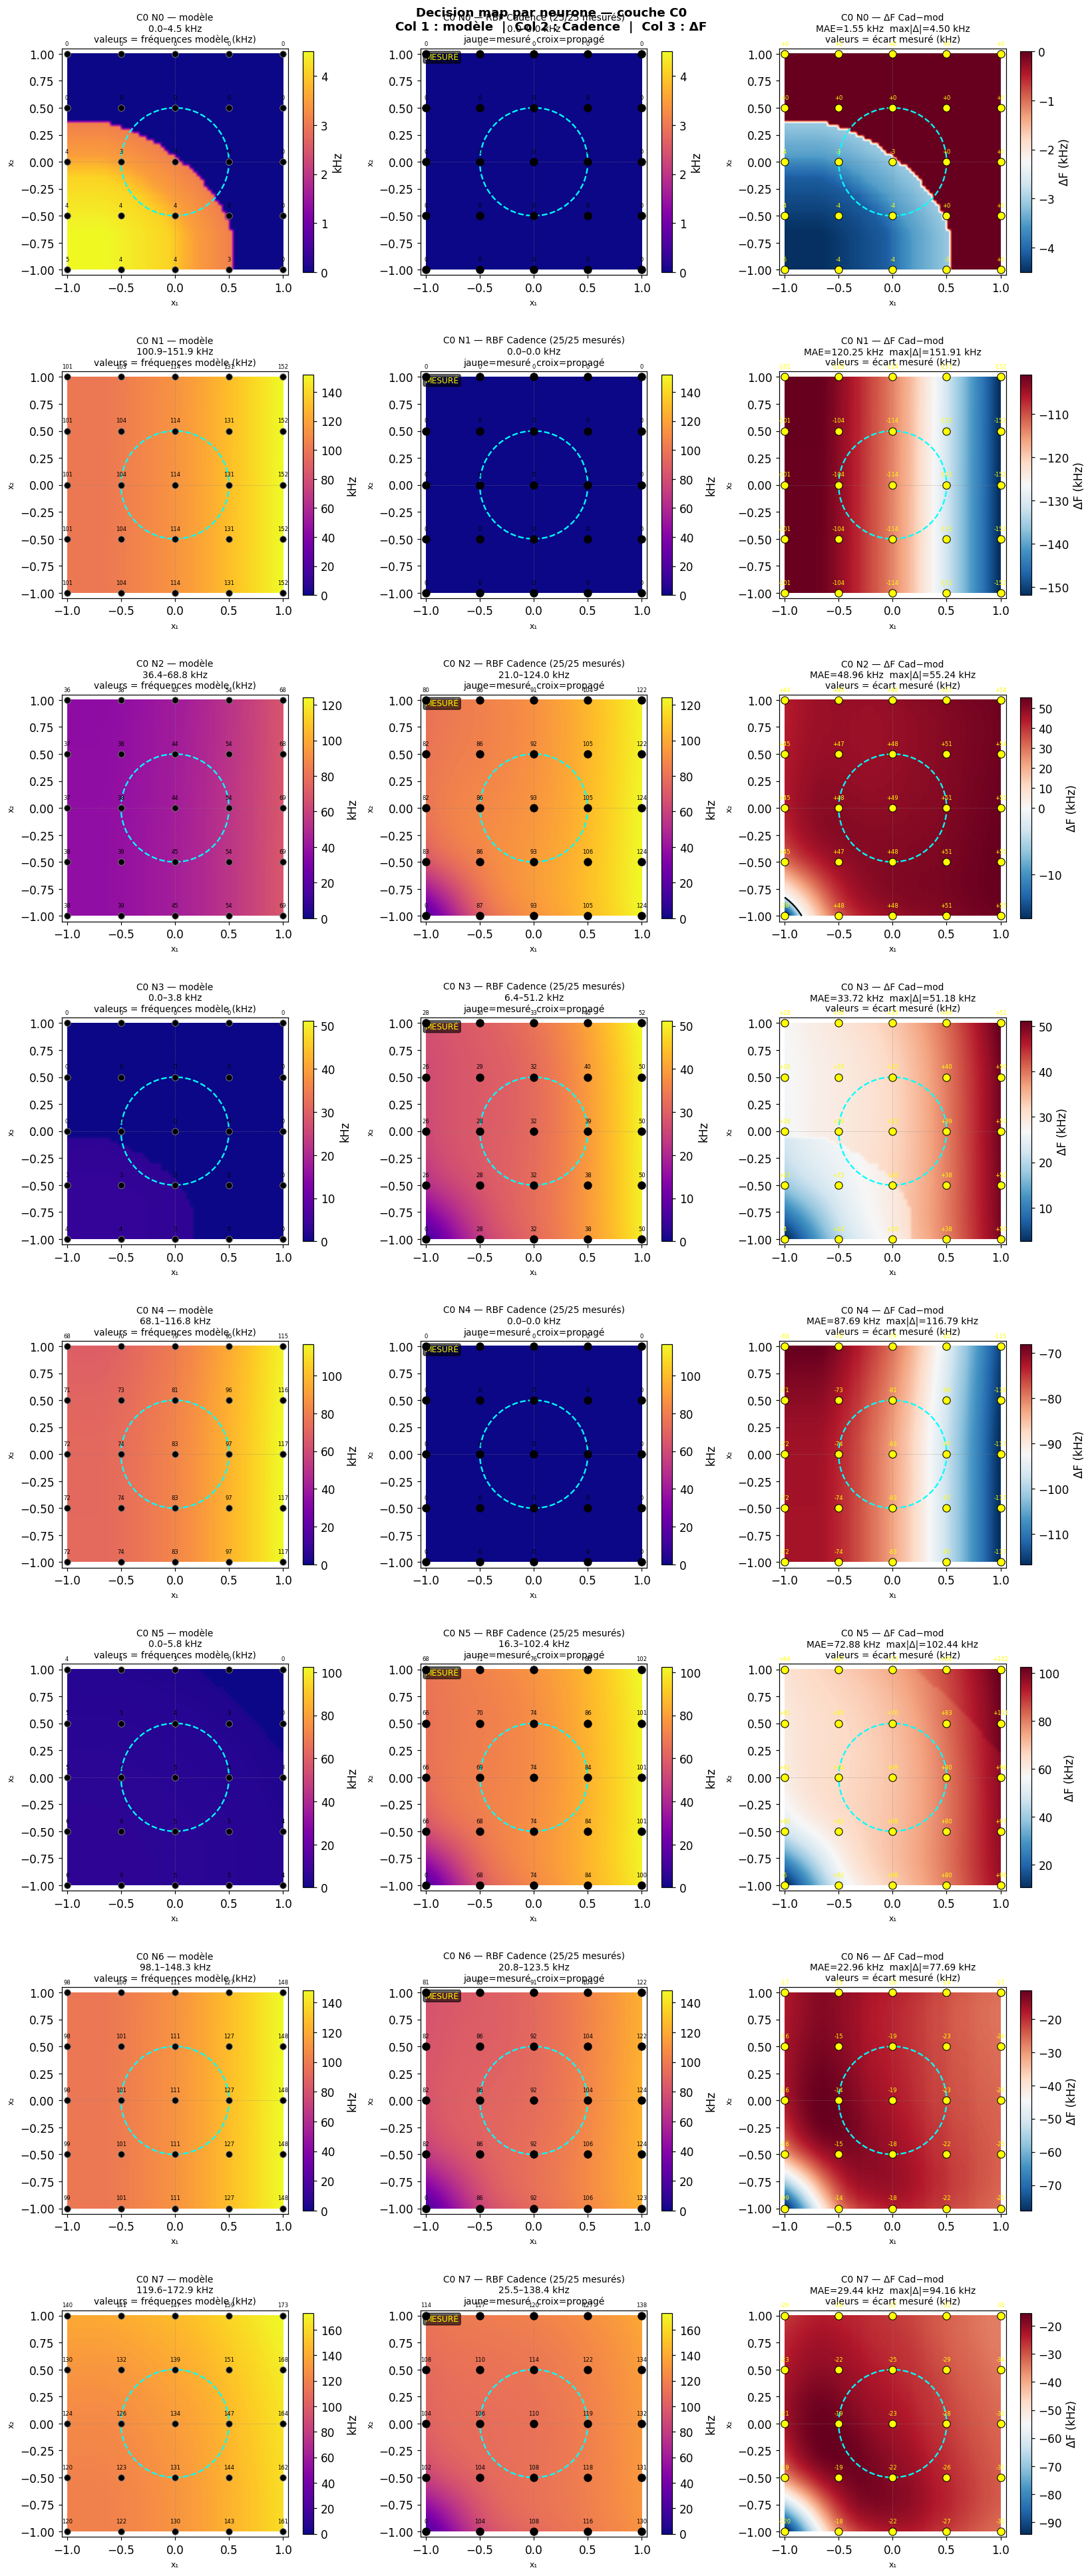

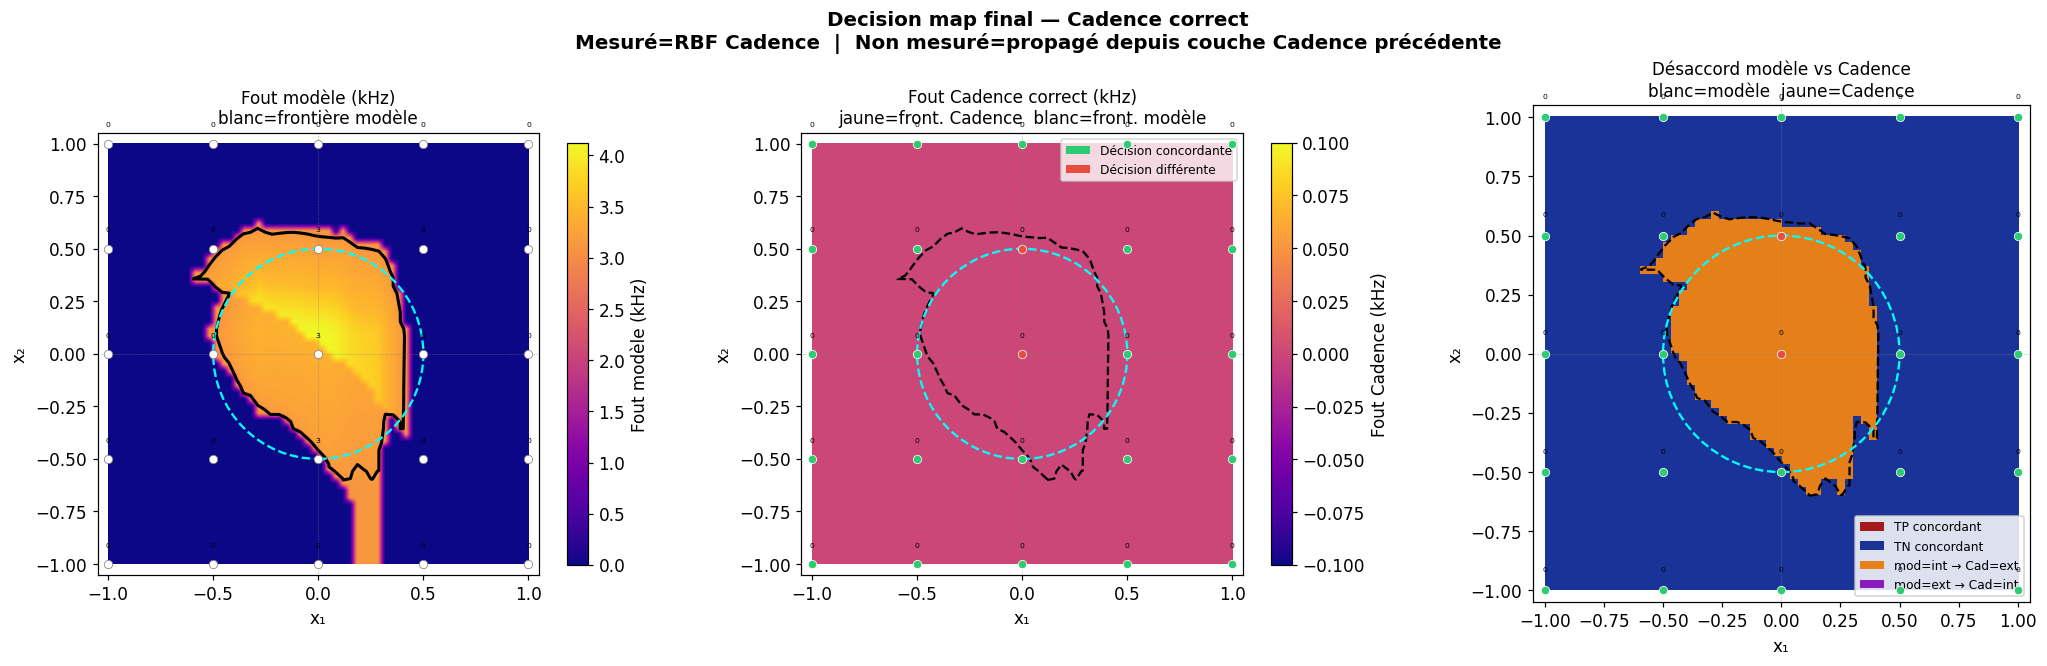


Surface intérieur — modèle          : 19.2%
Surface intérieur — Cadence correct : 0.0%
Zone de désaccord                   : 19.2%
Décalage surface                    : -19.2%


In [28]:
# ══════════════════════════════════════════════════════════════
# DECISION MAP CADENCE PUR — PROPAGATION CORRECTE
# Si couche Li est mesurée → on substitue les valeurs Cadence
# Si couche Li n'est pas mesurée → on propage depuis la couche
#   précédente (qui peut être Cadence ou modèle entrée)
# La sortie est toujours recalculée depuis la dernière couche
# cachée disponible.
# ══════════════════════════════════════════════════════════════
from scipy.interpolate import RBFInterpolator

N_MAP_CAD = 60

x1_cad = np.linspace(-1, 1, N_MAP_CAD)
x2_cad = np.linspace(-1, 1, N_MAP_CAD)
X1G_cad, X2G_cad = np.meshgrid(x1_cad, x2_cad)
query_cad = np.column_stack([X1G_cad.ravel(), X2G_cad.ravel()])
ext_cad   = [-1, 1, -1, 1]

pts_xy = np.array([[pt['x1'], pt['x2']] for pt in GRID_POINTS])

# ── Interpolation RBF par neurone mesuré ─────────────────────
# rbf_by_layer[li][j] = RBFInterpolator ou None si pas mesuré
print('Construction des interpolateurs RBF par neurone...')
rbf_by_layer = []
for li in range(N_HIDDEN_LAYERS):
    cad_key = f'cad_c{li}'
    rbf_layer = []
    for j in range(HIDDEN_SIZES[li]):
        pts_with_val = [(pt['x1'], pt['x2'], float(pt[cad_key][j]))
                        for pt in GRID_POINTS
                        if pt[cad_key][j] is not None]
        if len(pts_with_val) >= 3:
            xy_m  = np.array([[p[0], p[1]] for p in pts_with_val])
            fhz_m = np.array([p[2]          for p in pts_with_val])  # Hz
            rbf_j = RBFInterpolator(xy_m, fhz_m,
                                    kernel='thin_plate_spline',
                                    smoothing=0.3)
            rbf_layer.append(rbf_j)
        else:
            rbf_layer.append(None)   # neurone non mesuré
    rbf_by_layer.append(rbf_layer)
    n_meas = sum(1 for r in rbf_layer if r is not None)
    print(f'  C{li} : {n_meas}/{HIDDEN_SIZES[li]} neurones avec RBF Cadence')

# ── Vérification : quelles couches sont "toutes None" ────────
layer_has_cadence = []
for li in range(N_HIDDEN_LAYERS):
    has = any(r is not None for r in rbf_by_layer[li])
    layer_has_cadence.append(has)
    print(f'  C{li} mesurée : {has}')

# ══════════════════════════════════════════════════════════════
# PROPAGATION CADENCE CORRECTE — point par point
# Pour chaque point (x1, x2) :
#   1. Calculer Fin depuis les tensions (modèle entrée — pas de
#      mesure Cadence sur les entrées)
#   2. Pour chaque couche cachée li :
#      - Si RBF disponible pour neurone j → prendre valeur Cadence
#      - Sinon → propager depuis F_prev avec les synapses du modèle
#   3. Calculer la sortie depuis la dernière couche cachée
# ══════════════════════════════════════════════════════════════
def propagate_cadence_correct(x1, x2, rbf_by_layer, layers_config):
    """
    Propagation où chaque neurone mesuré par Cadence prend sa
    vraie valeur interpolée, et les non-mesurés sont calculés
    en propageant depuis la couche précédente (pas le modèle pur).

    Retourne : fout_cad (Hz), F_history (liste par couche)
    """
    # Entrée : modèle entrée (pas de mesure Cadence sur Vin→Fin)
    Vin = V_MIN + (np.array([x1, x2]) + 1.0) * (V_MAX - V_MIN) / 2.0
    F_cur = np.array([input_f_of_v(v) for v in Vin])
    F_history = [F_cur.copy()]

    for li, cfg in enumerate(layers_config):
        # Propagation normale depuis F_cur
        F_next, _, _ = layer_forward(
            F_cur,
            np.asarray(cfg['signs'],  int),
            np.asarray(cfg['widths'], float)
        )

        # Si couche cachée → substituer les neurones mesurés
        if li < N_HIDDEN_LAYERS:
            query_pt = np.array([[x1, x2]])
            for j in range(HIDDEN_SIZES[li]):
                rbf_j = rbf_by_layer[li][j]
                if rbf_j is not None:
                    # Valeur Cadence interpolée pour ce neurone
                    val_hz = float(rbf_j(query_pt)[0])
                    val_hz = max(0.0, val_hz)   # pas de fréquence négative
                    F_next[j] = val_hz
                # Sinon : F_next[j] reste la valeur propagée depuis
                # F_cur qui est déjà Cadence pour les couches précédentes

        F_history.append(F_next.copy())
        F_cur = F_next

    fout = float(F_cur[0])
    return fout, F_history


# ── Calcul des grilles ────────────────────────────────────────
print('\nCalcul grille Cadence correct...')
grid_cad_correct = np.zeros((N_MAP_CAD, N_MAP_CAD))
grid_mod_ref2    = np.zeros((N_MAP_CAD, N_MAP_CAD))

# Grilles par neurone pour visualisation
grids_cad_correct  = [[np.zeros((N_MAP_CAD, N_MAP_CAD))
                        for _ in range(HIDDEN_SIZES[li])]
                       for li in range(N_HIDDEN_LAYERS)]
grids_mod_correct  = [[np.zeros((N_MAP_CAD, N_MAP_CAD))
                        for _ in range(HIDDEN_SIZES[li])]
                       for li in range(N_HIDDEN_LAYERS)]

for ii in range(N_MAP_CAD):
    for jj in range(N_MAP_CAD):
        x1_q = x1_cad[jj]
        x2_q = x2_cad[ii]

        # Cadence correct
        fout_cad, F_hist_cad = propagate_cadence_correct(
            x1_q, x2_q, rbf_by_layer, layers_config
        )
        grid_cad_correct[ii, jj] = fout_cad / 1e3

        # Modèle pur (référence)
        Vc = V_MIN + (np.array([x1_q, x2_q]) + 1.0) * (V_MAX - V_MIN) / 2.0
        hFc, _, _ = propagate(Vc, layers_config)
        grid_mod_ref2[ii, jj] = hFc[-1][0] / 1e3

        # Grilles par neurone
        for li in range(N_HIDDEN_LAYERS):
            for j in range(HIDDEN_SIZES[li]):
                grids_cad_correct[li][j][ii, jj] = F_hist_cad[li+1][j] / 1e3
                grids_mod_correct[li][j][ii, jj]  = hFc[li+1][j] / 1e3

print('Terminé.')


# ── Decision maps par neurone ─────────────────────────────────
for li in range(N_HIDDEN_LAYERS):
    M = HIDDEN_SIZES[li]
    cad_key = f'cad_c{li}'

    fig, axes = plt.subplots(M, 3, figsize=(15, 4.5 * M), squeeze=False)
    fig.suptitle(
        f'Decision map par neurone — couche C{li}\n'
        f'Col 1 : modèle  |  Col 2 : Cadence  |  Col 3 : ΔF',
        fontsize=12, fontweight='bold'
    )

    for j in range(M):
        g_mod  = grids_mod_correct[li][j]
        g_cad  = grids_cad_correct[li][j]
        g_diff = g_cad - g_mod
        vmax_f = max(g_mod.max(), g_cad.max(), 0.1)
        norm_d = safe_norm(g_diff, vcenter=0)

        is_measured = rbf_by_layer[li][j] is not None
        n_meas = sum(1 for pt in GRID_POINTS
                     if pt[cad_key][j] is not None)

        def scatter_model(ax, li=li, j=j):
            """Points avec valeur MODÈLE sur la carte modèle."""
            for pt in GRID_POINTS:
                mod_val = pt['hF_mod'][li + 1][j] / 1e3
                ax.scatter(pt['x1'], pt['x2'],
                           c='black', s=40,
                           edgecolors='gray', linewidths=0.6, zorder=6)
                ax.text(pt['x1'], pt['x2'] + 0.08,
                        f'{mod_val:.0f}',
                        ha='center', fontsize=5.5,
                        color='black', zorder=7)

        def scatter_cadence(ax, li=li, j=j, cad_key=cad_key):
            """Points avec valeur CADENCE sur la carte Cadence.
            Jaune = mesuré avec valeur réelle.
            Croix grise = non mesuré (valeur propagée)."""
            for pt in GRID_POINTS:
                val = pt[cad_key][j]
                if val is not None:
                    # Mesuré → point jaune avec valeur Cadence
                    ax.scatter(pt['x1'], pt['x2'],
                               c='black', s=55,
                               edgecolors='black', linewidths=0.7, zorder=6)
                    ax.text(pt['x1'], pt['x2'] + 0.08,
                            f'{float(val)/1e3:.0f}',
                            ha='center', fontsize=5.5,
                            color='black', zorder=7)
                else:
                    # Non mesuré → croix grise (valeur propagée)
                    ax.scatter(pt['x1'], pt['x2'],
                               c='gray', s=20, marker='x',
                               linewidths=0.8, zorder=6)

        def scatter_diff(ax, li=li, j=j, cad_key=cad_key):
            """Points avec écart ΔF sur la carte diff."""
            for pt in GRID_POINTS:
                val = pt[cad_key][j]
                mod_val = pt['hF_mod'][li + 1][j] / 1e3
                if val is not None:
                    cad_val = float(val) / 1e3
                    diff    = cad_val - mod_val
                    ax.scatter(pt['x1'], pt['x2'],
                               c='yellow', s=55,
                               edgecolors='black', linewidths=0.7, zorder=6)
                    ax.text(pt['x1'], pt['x2'] + 0.08,
                            f'{diff:+.0f}',
                            ha='center', fontsize=5.5,
                            color='yellow', zorder=7)
                else:
                    ax.scatter(pt['x1'], pt['x2'],
                               c='gray', s=20, marker='x',
                               linewidths=0.8, zorder=6)

        def base_decor2(ax):
            ax.add_patch(Circle((0, 0), DISK_R, color='cyan',
                                 fill=False, lw=1.5, ls='--', zorder=5))
            ax.axhline(0, color='gray', lw=0.4, ls=':')
            ax.axvline(0, color='gray', lw=0.4, ls=':')
            ax.set_xlim(-1.05, 1.05); ax.set_ylim(-1.05, 1.05)
            ax.set_aspect('equal')
            ax.set_xlabel('x₁', fontsize=8)
            ax.set_ylabel('x₂', fontsize=8)

        # ── Col 0 : modèle — points avec valeurs modèle ──────
        ax = axes[j, 0]
        im = ax.imshow(g_mod, origin='lower', extent=ext_cad,
                       aspect='equal', cmap='plasma',
                       vmin=0, vmax=vmax_f, interpolation='bilinear')
        plt.colorbar(im, ax=ax, label='kHz', shrink=0.85)
        scatter_model(ax)   # valeurs modèle sur carte modèle
        base_decor2(ax)
        ax.set_title(f'C{li} N{j} — modèle\n'
                     f'{g_mod.min():.1f}–{g_mod.max():.1f} kHz\n'
                     f'valeurs = fréquences modèle (kHz)',
                     fontsize=9)

        # ── Col 1 : Cadence — points avec valeurs Cadence ────
        ax = axes[j, 1]
        im = ax.imshow(g_cad, origin='lower', extent=ext_cad,
                       aspect='equal', cmap='plasma',
                       vmin=0, vmax=vmax_f, interpolation='bilinear')
        plt.colorbar(im, ax=ax, label='kHz', shrink=0.85)
        scatter_cadence(ax)   # valeurs Cadence sur carte Cadence
        base_decor2(ax)
        badge = f'RBF Cadence ({n_meas}/25 mesurés)' if is_measured \
                else f'Propagé depuis C{li-1} Cadence'
        ax.set_title(f'C{li} N{j} — {badge}\n'
                     f'{g_cad.min():.1f}–{g_cad.max():.1f} kHz\n'
                     f'jaune=mesuré  croix=propagé',
                     fontsize=9)
        ax.text(0.02, 0.98,
                'MESURÉ' if is_measured else 'PROPAGÉ',
                transform=ax.transAxes, fontsize=8, va='top',
                color='yellow' if is_measured else 'cyan',
                bbox=dict(boxstyle='round,pad=0.2',
                          fc='black', alpha=0.6))

        # ── Col 2 : ΔF — points avec écart ───────────────────
        ax = axes[j, 2]
        im = ax.imshow(g_diff, origin='lower', extent=ext_cad,
                       aspect='equal', cmap='RdBu_r',
                       norm=norm_d, interpolation='bilinear')
        plt.colorbar(im, ax=ax, label='ΔF (kHz)', shrink=0.85)
        ax.contour(x1_cad, x2_cad, g_diff,
                   levels=[0], colors='black', linewidths=1.5)
        scatter_diff(ax)   # écarts sur carte diff
        base_decor2(ax)
        vals_ec = [pt[f'ecart_c{li}'][j] for pt in GRID_POINTS
                   if pt[f'ecart_c{li}'][j] is not None]
        mae_n = np.mean(np.abs(vals_ec)) if vals_ec else 0.0
        ax.set_title(f'C{li} N{j} — ΔF Cad−mod\n'
                     f'MAE={mae_n:.2f} kHz  '
                     f'max|Δ|={np.nanmax(np.abs(g_diff)):.2f} kHz\n'
                     f'valeurs = écart mesuré (kHz)',
                     fontsize=9)

    plt.tight_layout()
    plt.show()

# ── Decision map final ────────────────────────────────────────
dec_cad_c = (grid_cad_correct >= THRESHOLD_HZ / 1e3).astype(int)
dec_mod_c  = (grid_mod_ref2   >= THRESHOLD_HZ / 1e3).astype(int)

rgb_c = np.zeros((N_MAP_CAD, N_MAP_CAD, 3))
rgb_c[(dec_mod_c==1)&(dec_cad_c==1)] = [0.65, 0.10, 0.10]
rgb_c[(dec_mod_c==0)&(dec_cad_c==0)] = [0.10, 0.20, 0.60]
rgb_c[(dec_mod_c==1)&(dec_cad_c==0)] = [0.90, 0.50, 0.10]
rgb_c[(dec_mod_c==0)&(dec_cad_c==1)] = [0.55, 0.10, 0.75]

fig, axes = plt.subplots(1, 3, figsize=(19, 6))
fig.suptitle(
    'Decision map final — Cadence correct\n'
    'Mesuré=RBF Cadence  |  Non mesuré=propagé depuis couche Cadence précédente',
    fontsize=13, fontweight='bold'
)

def decor_fin2(ax, title, show_model_pts=False, show_cadence_pts=False):
    ax.add_patch(Circle((0, 0), DISK_R, color='cyan',
                         fill=False, lw=1.5, ls='--', zorder=5))
    ax.axhline(0, color='gray', lw=0.4, ls=':')
    ax.axvline(0, color='gray', lw=0.4, ls=':')
    ax.set_xlim(-1.05, 1.05); ax.set_ylim(-1.05, 1.05)
    ax.set_aspect('equal')
    ax.set_xlabel('x₁'); ax.set_ylabel('x₂')
    ax.set_title(title, fontsize=11)
    if show_model_pts:
        # Points blancs = positions modèle sur carte modèle
        for pt in GRID_POINTS:
            fmod_val = pt['fmod'] / 1e3
            ax.scatter(pt['x1'], pt['x2'],
                       c='white', s=30,
                       edgecolors='gray', linewidths=0.5, zorder=6)
            ax.text(pt['x1'], pt['x2'] + 0.08,
                    f'{fmod_val:.0f}',
                    ha='center', fontsize=5,
                    color='black', zorder=7)
    if show_cadence_pts:
        # Points jaunes = positions Cadence sur carte Cadence
        for pt in GRID_POINTS:
            fhyb_val = pt['fhyb'] / 1e3
            c = '#2ecc71' if pt['agree'] else '#e74c3c'
            ax.scatter(pt['x1'], pt['x2'],
                       c=c, s=30,
                       edgecolors='white', linewidths=0.5, zorder=6)
            ax.text(pt['x1'], pt['x2'] + 0.08,
                    f'{fhyb_val:.0f}',
                    ha='center', fontsize=5,
                    color='black', zorder=7)

# 1. Fout modèle — points modèle
ax = axes[0]
im = ax.imshow(grid_mod_ref2, origin='lower', extent=ext_cad,
               aspect='equal', cmap='plasma', vmin=0, interpolation='bilinear')
plt.colorbar(im, ax=ax, label='Fout modèle (kHz)', shrink=0.85)
ax.contour(x1_cad, x2_cad, grid_mod_ref2,
           levels=[THRESHOLD_HZ/1e3], colors='black', linewidths=2)
decor_fin2(ax, 'Fout modèle (kHz)\nblanc=frontière modèle',
           show_model_pts=True)

# 2. Fout Cadence — points Cadence
ax = axes[1]
im = ax.imshow(grid_cad_correct, origin='lower', extent=ext_cad,
               aspect='equal', cmap='plasma', vmin=0, interpolation='bilinear')
plt.colorbar(im, ax=ax, label='Fout Cadence (kHz)', shrink=0.85)
ax.contour(x1_cad, x2_cad, grid_cad_correct,
           levels=[THRESHOLD_HZ/1e3], colors='black', linewidths=2.5)
ax.contour(x1_cad, x2_cad, grid_mod_ref2,
           levels=[THRESHOLD_HZ/1e3], colors='black',
           linewidths=1.5, linestyles='--')
decor_fin2(ax, 'Fout Cadence correct (kHz)\njaune=front. Cadence  blanc=front. modèle',
           show_cadence_pts=True)
ax.legend(handles=[
    Patch(facecolor='#2ecc71', label='Décision concordante'),
    Patch(facecolor='#e74c3c', label='Décision différente'),
], fontsize=8, loc='upper right', framealpha=0.8)

# 3. Désaccord — points des deux
ax = axes[2]
ax.imshow(rgb_c, origin='lower', extent=ext_cad,
          aspect='equal', interpolation='nearest')
ax.contour(x1_cad, x2_cad, grid_mod_ref2,
           levels=[THRESHOLD_HZ/1e3], colors='black',
           linewidths=1.5, linestyles='--')
ax.contour(x1_cad, x2_cad, grid_cad_correct,
           levels=[THRESHOLD_HZ/1e3], colors='black', linewidths=2)
decor_fin2(ax, 'Désaccord modèle vs Cadence\nblanc=modèle  jaune=Cadence',
           show_cadence_pts=True)
ax.legend(handles=[
    Patch(facecolor=[0.65,0.10,0.10], label='TP concordant'),
    Patch(facecolor=[0.10,0.20,0.60], label='TN concordant'),
    Patch(facecolor=[0.90,0.50,0.10], label='mod=int → Cad=ext'),
    Patch(facecolor=[0.55,0.10,0.75], label='mod=ext → Cad=int'),
], fontsize=8, loc='lower right', framealpha=0.85)

plt.tight_layout()
plt.show()

pct_m = dec_mod_c.mean()  * 100
pct_c = dec_cad_c.mean()  * 100
pct_d = (dec_mod_c != dec_cad_c).mean() * 100
print(f'\nSurface intérieur — modèle          : {pct_m:.1f}%')
print(f'Surface intérieur — Cadence correct : {pct_c:.1f}%')
print(f'Zone de désaccord                   : {pct_d:.1f}%')
print(f'Décalage surface                    : {pct_c - pct_m:+.1f}%')
